In [6]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [2]:
import ctypes, os
import numpy as np
import matplotlib.pyplot as plt

cpp_lib = ctypes.CDLL(os.path.abspath("./libPA_V2.dll"))


double_ptr = ctypes.POINTER(ctypes.c_double)

cpp_lib.create_svm_model.argtypes = [
    ctypes.c_int32, ctypes.c_double, ctypes.c_int32, ctypes.c_int32
]
cpp_lib.create_svm_model.restype = ctypes.c_void_p

cpp_lib.train_svm_model.argtypes = [
    ctypes.c_void_p, double_ptr, double_ptr,
    ctypes.c_int32, ctypes.c_int32, ctypes.c_double
]
cpp_lib.train_svm_model.restype = ctypes.c_int32

cpp_lib.decision_svm.argtypes = [ctypes.c_void_p, double_ptr]
cpp_lib.decision_svm.restype = ctypes.c_double

cpp_lib.get_num_support_vectors.argtypes = [ctypes.c_void_p]
cpp_lib.get_num_support_vectors.restype = ctypes.c_int32

cpp_lib.get_support_vectors.argtypes = [ctypes.c_void_p, double_ptr]
cpp_lib.get_support_vectors.restype = None

cpp_lib.get_W0.argtypes = [ctypes.c_void_p]
cpp_lib.get_W0.restype = ctypes.c_double

cpp_lib.destroy_svm_model.argtypes = [ctypes.c_void_p]
cpp_lib.destroy_svm_model.restype = None

linear, polynomial, rbf = 0, 1, 2
kernel_names = {
    linear: "linear",
    polynomial: "poly",
    rbf: "rbf"
}
os.makedirs("figures", exist_ok=True)


In [3]:
# convertir le tableau numPy en pointeur c++
def ptr(a):
    return a.ctypes.data_as(double_ptr)


def train_svm(X, Y, kernel, C=0.0, gamma=1.0, degree=2):
    """C = 0 -> hard margin. C > 0 -> soft margin."""
    X_c = np.ascontiguousarray(X, dtype=np.float64)
    Y_c = np.ascontiguousarray(np.ravel(Y), dtype=np.float64)
    n, d = X_c.shape
    model = cpp_lib.create_svm_model(d, gamma, degree, kernel)
    status = cpp_lib.train_svm_model(model, ptr(X_c), ptr(Y_c), n, d, C)
    k = cpp_lib.get_num_support_vectors(model)
    sv = np.zeros((k, d))
    if k > 0:
        cpp_lib.get_support_vectors(model, ptr(sv))
    return {"model": model, "status": status, "n_sv": k, "sv": sv,
            "W0": cpp_lib.get_W0(model)}


def decisions(models, P):
    P = np.ascontiguousarray(P, dtype=np.float64)
    return np.array([[cpp_lib.decision_svm(m["model"], ptr(np.ascontiguousarray(p))) for m in models] for p in P])


def predict(models, P):
    D = decisions(models, P)
    return np.where(D[:, 0] > 0, 1, -1) if len(models) == 1 else D.argmax(1)


def plot_svm(title, X, Y, models, filename):
    multi = (Y.ndim == 2 and Y.shape[1] > 1)
    y_true = Y.argmax(1) if multi else np.ravel(Y)
    acc = np.mean(predict(models, X) == y_true) * 100
    n_sv = sum(m["n_sv"] for m in models)
    print(f"{title} | acc={acc:.1f}% | #SV={n_sv} | W0={[round(m['W0'], 3) for m in models]} | status={[m['status'] for m in models]}")
    margin = 0.3
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - margin, X[:, 0].max() + margin, 100),
                         np.linspace(X[:, 1].min() - margin, X[:, 1].max() + margin, 100))
    Z = predict(models, np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure(figsize=(5, 5))
    if multi:
        k = Y.shape[1]
        plt.contourf(xx, yy, Z, levels=np.arange(-0.5, k, 1), colors=["blue", "red", "green"][:k], alpha=0.25)
        colors = np.array(["blue", "red", "green"])[y_true]
    else:
        plt.contourf(xx, yy, Z, levels=[-2, 0, 2], colors=["red", "blue"], alpha=0.25)
        colors = np.where(y_true > 0, "blue", "red")
    plt.scatter(X[:, 0], X[:, 1], c=colors, edgecolors="k")
    for m in models:
        if m["n_sv"] > 0:
            plt.scatter(m["sv"][:, 0], m["sv"][:, 1], s=140, facecolors="none", edgecolors="k", linewidths=1.5)
    plt.title(f"{title}\nacc={acc:.1f}%  #SV={n_sv}", fontsize=9)
    plt.tight_layout()
    plt.savefig(f"figures/{filename}.png", dpi=130)
    plt.show()
    for m in models:
        cpp_lib.destroy_svm_model(m["model"])
    return acc, n_sv


def run_case(case, X, Y, configs, seed=None):
    multi = (Y.ndim == 2 and Y.shape[1] > 1)
    for kernel, C, gamma, degree in configs:
        if multi:
            models = [train_svm(X, Y[:, k], kernel, C, gamma, degree) for k in range(Y.shape[1])]
        else:
            models = [train_svm(X, Y, kernel, C, gamma, degree)]
        name = f"{case}_{kernel_names[kernel]}_seed{seed}_C{C}_gamma{gamma}_Q{degree}"
        plot_svm(f"{case} | {kernel_names[kernel]} C={C} gamma={gamma} Q={degree}", X, Y, models, name)



## Classification

### Linear Simple :
        Linear Model : OK
        MLP (2, 1)   : OK

In [12]:
X = np.array([[1, 1], [2, 3], [3, 3]])
Y = np.array([1, -1, -1])

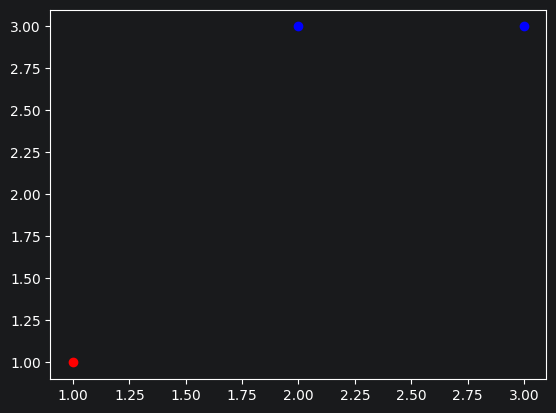

<Figure size 640x480 with 0 Axes>

In [13]:
plt.scatter(X[0, 0], X[0, 1], color='red')
plt.scatter(X[1:3,0], X[1:3,1], color='blue')
plt.show()
plt.clf()

## Exp 1 - Effect of kernel

Linear_Simple | linear C=1.0 gamma=1.0 Q=2 | acc=100.0% | #SV=2 | W0=[2.2] | status=[0]


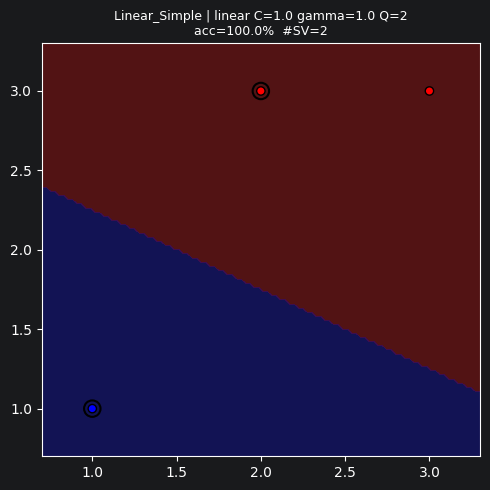

Linear_Simple | poly C=1.0 gamma=1.0 Q=2 | acc=100.0% | #SV=2 | W0=[1.406] | status=[0]


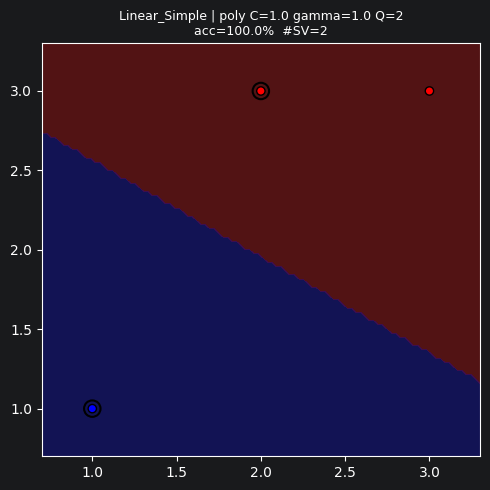

Linear_Simple | rbf C=1.0 gamma=1.0 Q=2 | acc=100.0% | #SV=3 | W0=[-0.32] | status=[0]


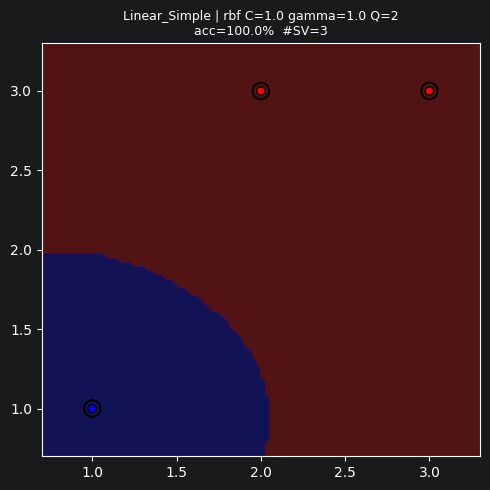

In [14]:
configs = [
    (linear, 1.0, 1.0, 2),
    (polynomial, 1.0, 1.0, 2),
    (rbf, 1.0, 1.0, 2)
]
run_case("Linear_Simple", X, Y, configs)

## Exp 2 - Effect of C

Linear_Simple_C | linear C=0 gamma=1 Q=2 | acc=100.0% | #SV=2 | W0=[2.2] | status=[0]


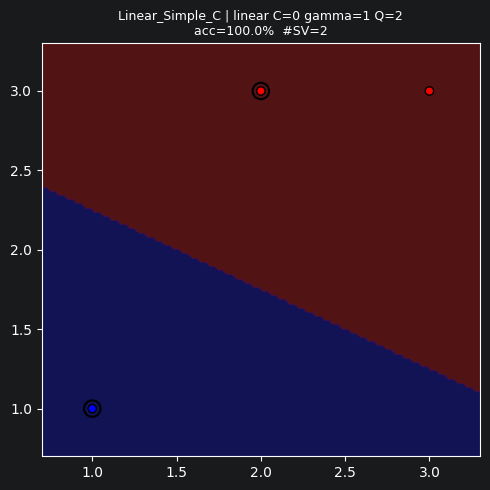

Linear_Simple_C | linear C=0.1 gamma=1 Q=2 | acc=33.3% | #SV=2 | W0=[1.3] | status=[0]


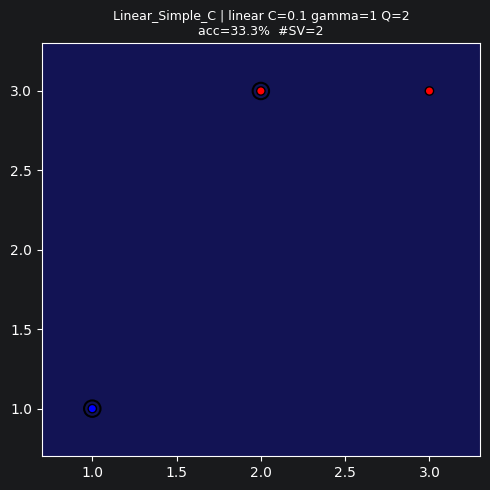

Linear_Simple_C | linear C=1 gamma=1 Q=2 | acc=100.0% | #SV=2 | W0=[2.2] | status=[0]


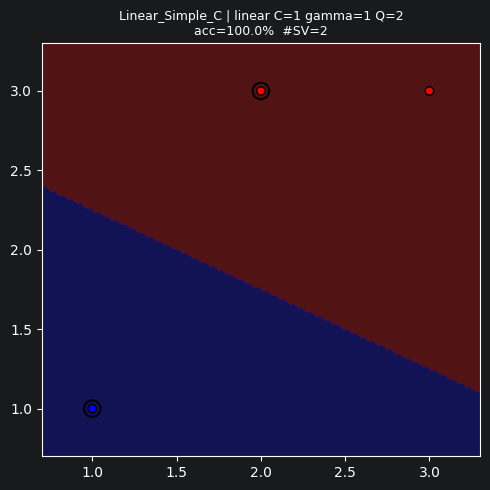

Linear_Simple_C | linear C=10 gamma=1 Q=2 | acc=100.0% | #SV=2 | W0=[2.2] | status=[0]


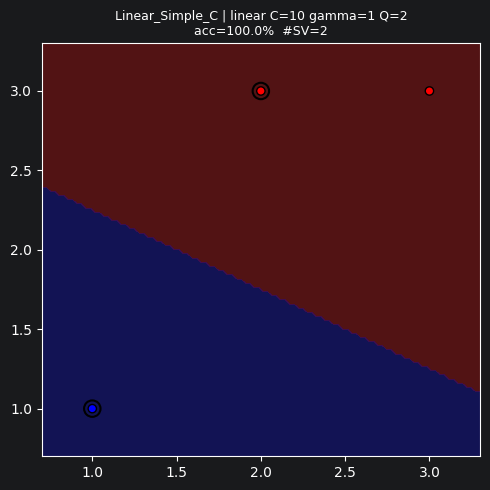

Linear_Simple_C | poly C=0 gamma=1 Q=2 | acc=100.0% | #SV=2 | W0=[1.406] | status=[0]


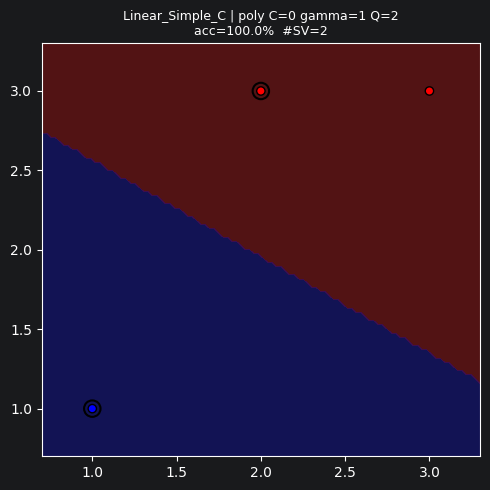

Linear_Simple_C | poly C=0.1 gamma=1 Q=2 | acc=100.0% | #SV=2 | W0=[1.406] | status=[0]


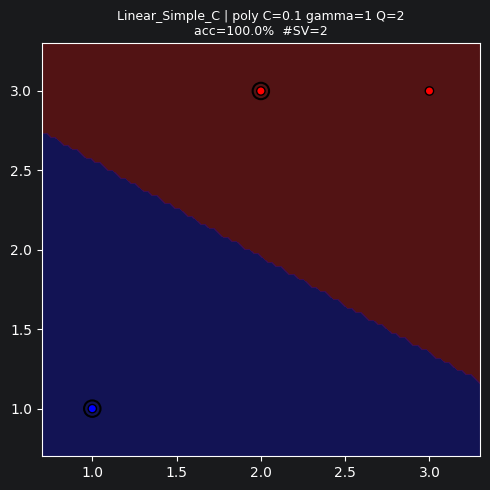

Linear_Simple_C | poly C=1 gamma=1 Q=2 | acc=100.0% | #SV=2 | W0=[1.406] | status=[0]


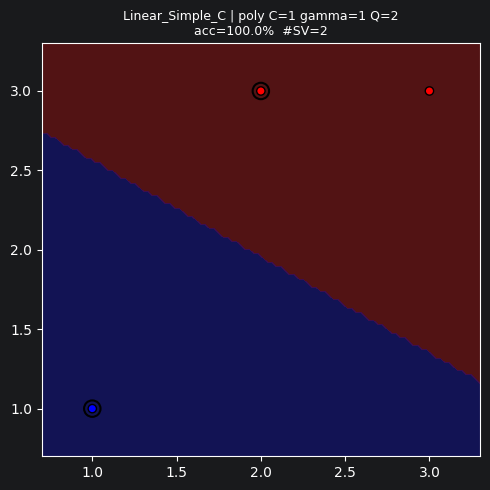

Linear_Simple_C | poly C=10 gamma=1 Q=2 | acc=100.0% | #SV=2 | W0=[1.406] | status=[0]


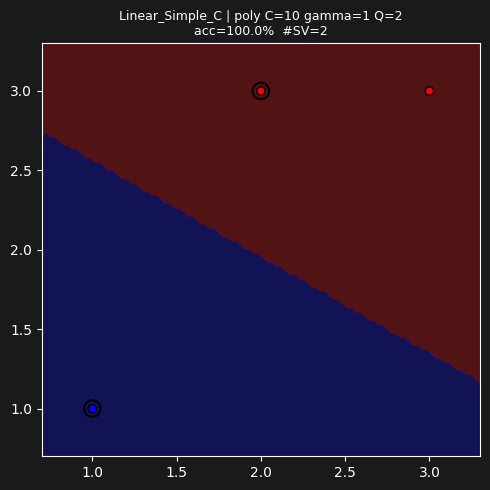

Linear_Simple_C | rbf C=0 gamma=1 Q=2 | acc=100.0% | #SV=3 | W0=[-0.188] | status=[0]


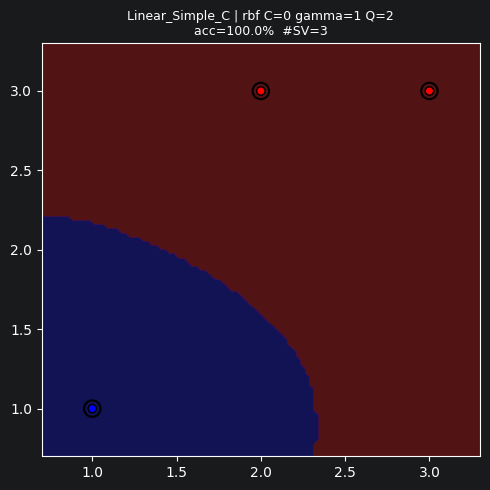

Linear_Simple_C | rbf C=0.1 gamma=1 Q=2 | acc=66.7% | #SV=3 | W0=[-0.932] | status=[0]


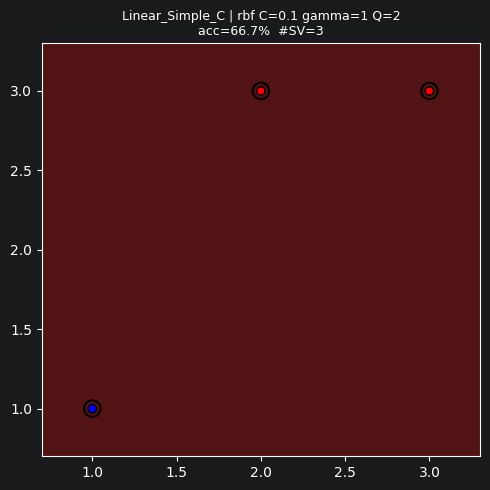

Linear_Simple_C | rbf C=1 gamma=1 Q=2 | acc=100.0% | #SV=3 | W0=[-0.32] | status=[0]


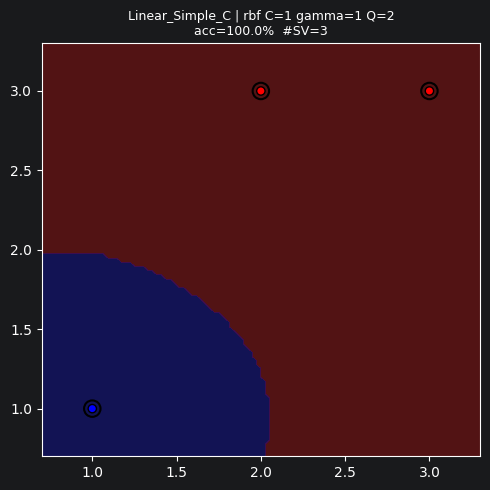

Linear_Simple_C | rbf C=10 gamma=1 Q=2 | acc=100.0% | #SV=3 | W0=[-0.188] | status=[0]


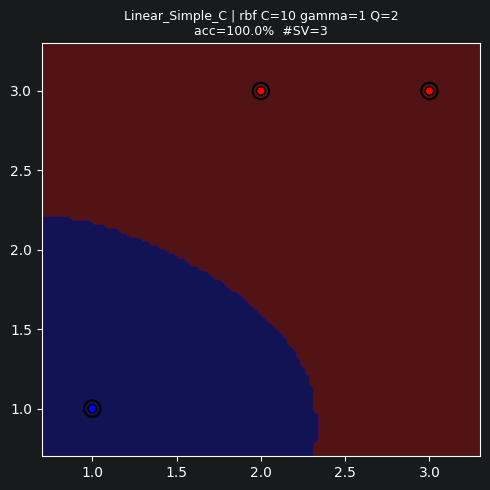

In [17]:
configs = [
    (linear, 0, 1, 2),
    (linear, 0.1, 1, 2),
    (linear, 1, 1, 2),
    (linear, 10, 1, 2),

    (polynomial, 0, 1, 2),
    (polynomial, 0.1, 1, 2),
    (polynomial, 1, 1, 2),
    (polynomial, 10, 1, 2),

    (rbf, 0, 1, 2),
    (rbf, 0.1, 1, 2),
    (rbf, 1, 1, 2),
    (rbf, 10, 1, 2)
]

run_case("Linear_Simple_C", X, Y, configs)

## Experiment 3 - polynomial degree

Linear_Simple_Degree | poly C=10 gamma=1 Q=2 | acc=100.0% | #SV=2 | W0=[1.406] | status=[0]


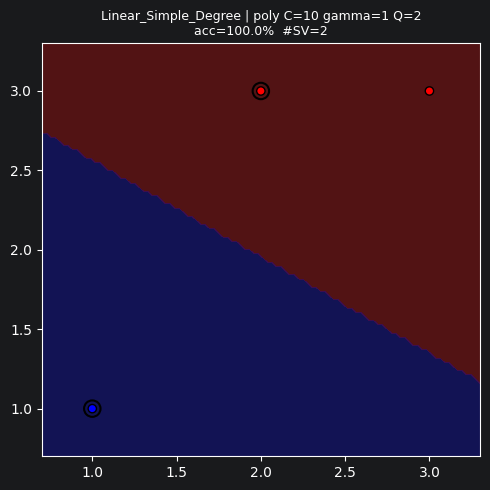

Linear_Simple_Degree | poly C=10 gamma=1 Q=3 | acc=100.0% | #SV=2 | W0=[1.162] | status=[0]


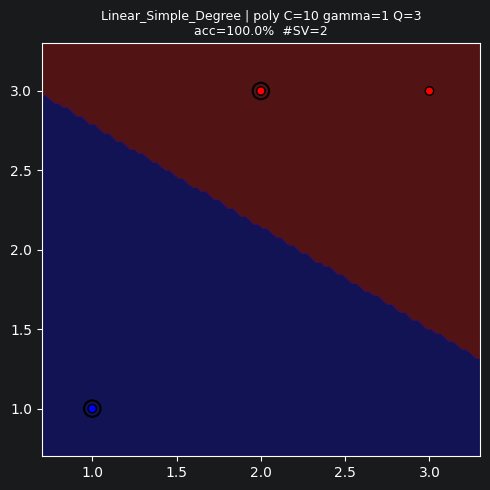

Linear_Simple_Degree | poly C=10 gamma=1 Q=4 | acc=100.0% | #SV=2 | W0=[1.068] | status=[0]


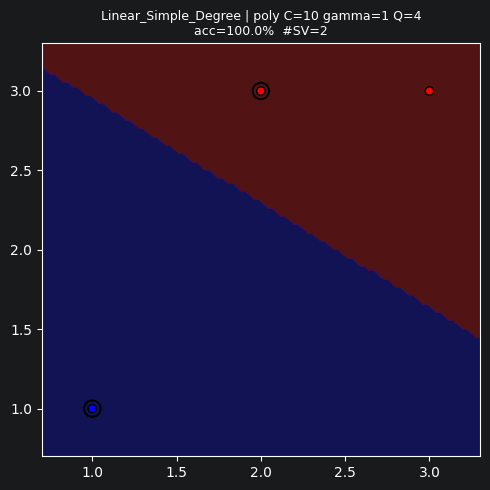

In [18]:
configs = [
    (polynomial, 10, 1, 2),
    (polynomial, 10, 1, 3),
    (polynomial, 10, 1, 4)
]

run_case("Linear_Simple_Degree", X, Y, configs)

## Exp 4 - Effect of RBF gamma

Linear_Simple_Gamma | rbf C=10 gamma=0.01 Q=2 | acc=66.7% | #SV=2 | W0=[0.512] | status=[0]


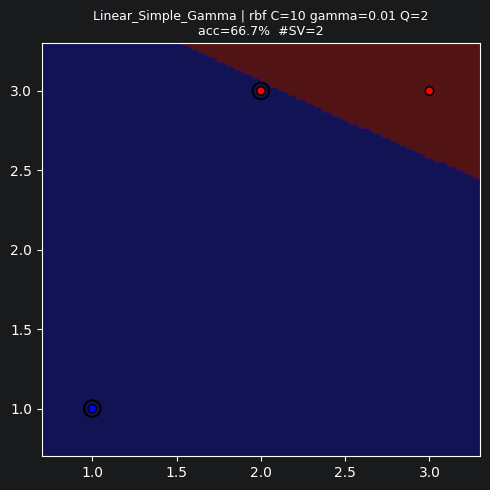

Linear_Simple_Gamma | rbf C=10 gamma=0.1 Q=2 | acc=100.0% | #SV=2 | W0=[0.0] | status=[0]


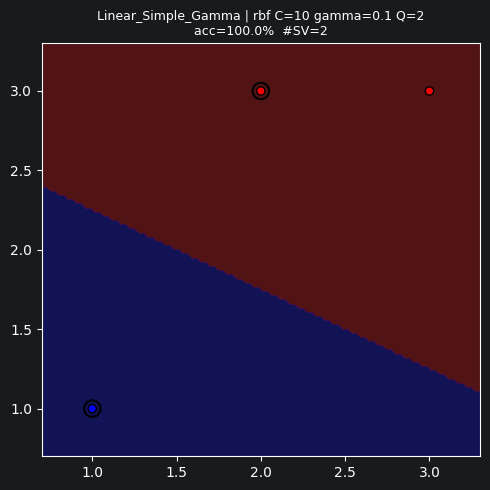

Linear_Simple_Gamma | rbf C=10 gamma=1 Q=2 | acc=100.0% | #SV=3 | W0=[-0.188] | status=[0]


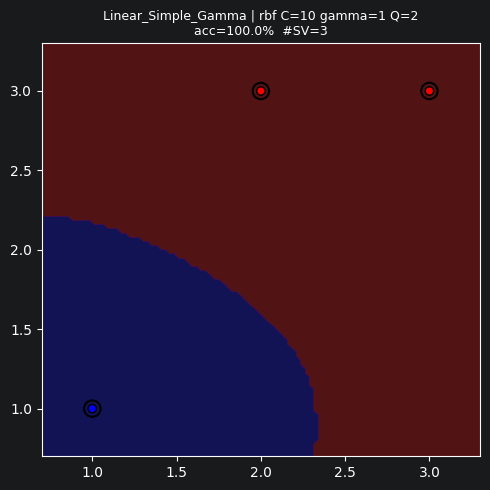

Linear_Simple_Gamma | rbf C=10 gamma=10 Q=2 | acc=100.0% | #SV=3 | W0=[-0.333] | status=[0]


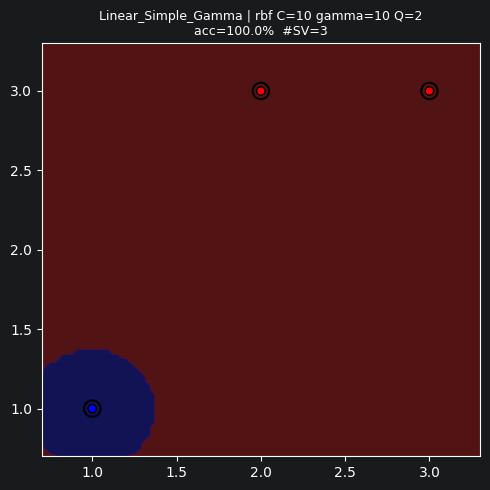

In [19]:
configs = [
    (rbf, 10, 0.01, 2),
    (rbf, 10, 0.1, 2),
    (rbf, 10, 1, 2),
    (rbf, 10, 10, 2)
]

run_case("Linear_Simple_Gamma", X, Y, configs)

## Linear Multiple :
        Linear Model : OK
        MLP (2, 1)   : OK

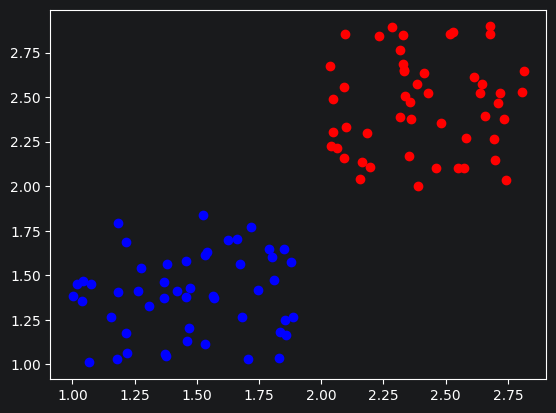

<Figure size 640x480 with 0 Axes>

In [27]:
X = np.concatenate([np.random.random((50,2)) * 0.9 + np.array([1, 1]), np.random.random((50,2)) * 0.9 + np.array([2, 2])])
Y = np.concatenate([np.ones((50, 1)), np.ones((50, 1)) * -1.0])
plt.scatter(X[0:50, 0], X[0:50, 1], color='blue')
plt.scatter(X[50:100,0], X[50:100,1], color='red')
plt.show()
plt.clf()

### Exp 1 - Kernel

Linear_Multiple | linear C=1.0 gamma=1.0 Q=2 | acc=100.0% | #SV=12 | W0=[8.397] | status=[0]


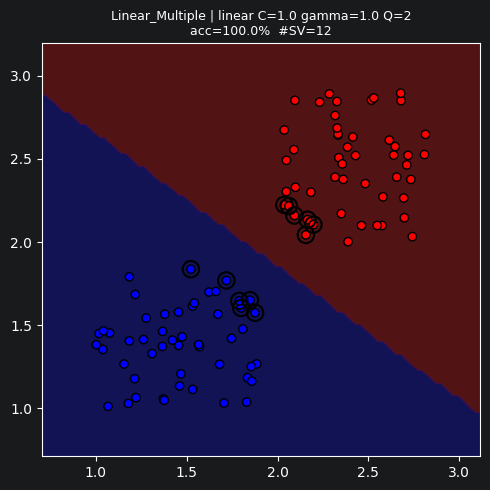

Linear_Multiple | poly C=1.0 gamma=1.0 Q=2 | acc=100.0% | #SV=3 | W0=[5.842] | status=[0]


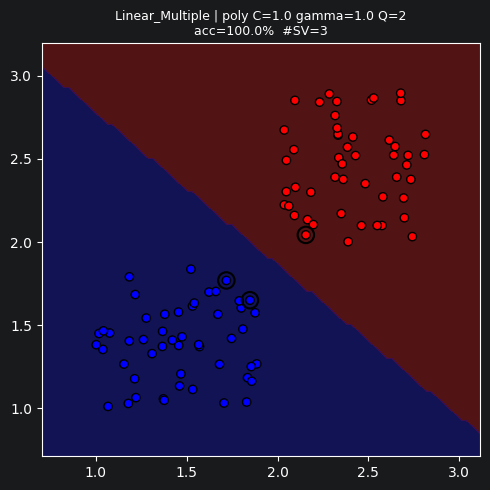

Linear_Multiple | rbf C=1.0 gamma=1.0 Q=2 | acc=100.0% | #SV=9 | W0=[0.063] | status=[0]


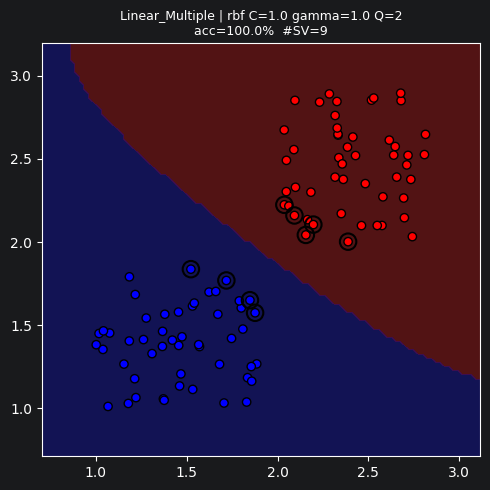

In [28]:
configs = [
    (linear, 1.0, 1.0, 2),
    (polynomial, 1.0, 1.0, 2),
    (rbf, 1.0, 1.0, 2)
]
run_case("Linear_Multiple", X, Y, configs)

### Exp 2 - Effect of C

Linear_Multiple | linear C=0.1 gamma=1 Q=2 | acc=100.0% | #SV=38 | W0=[4.354] | status=[0]


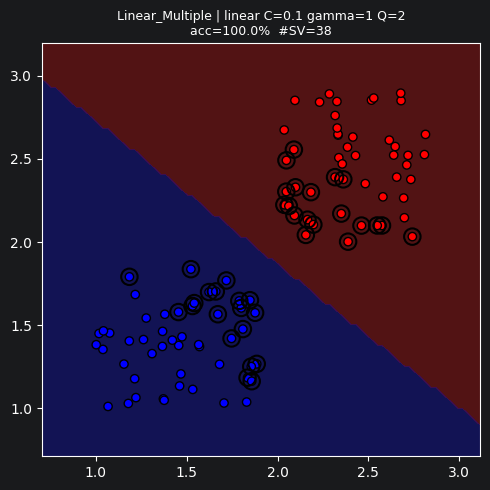

Linear_Multiple | linear C=1 gamma=1 Q=2 | acc=100.0% | #SV=12 | W0=[8.397] | status=[0]


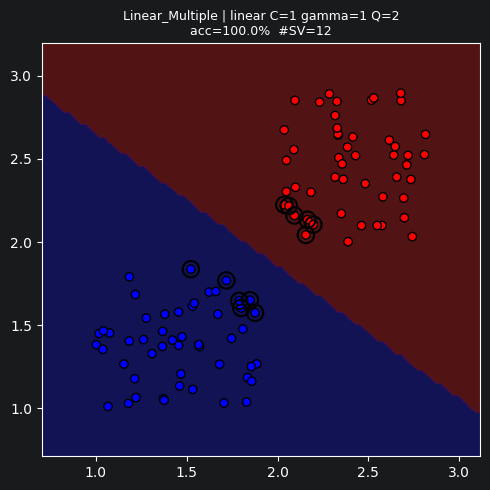

Linear_Multiple | linear C=10 gamma=1 Q=2 | acc=100.0% | #SV=3 | W0=[10.909] | status=[0]


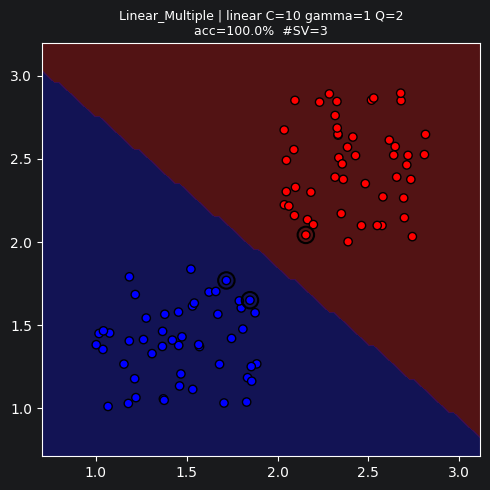

Linear_Multiple | poly C=0.1 gamma=1 Q=2 | acc=100.0% | #SV=6 | W0=[4.981] | status=[0]


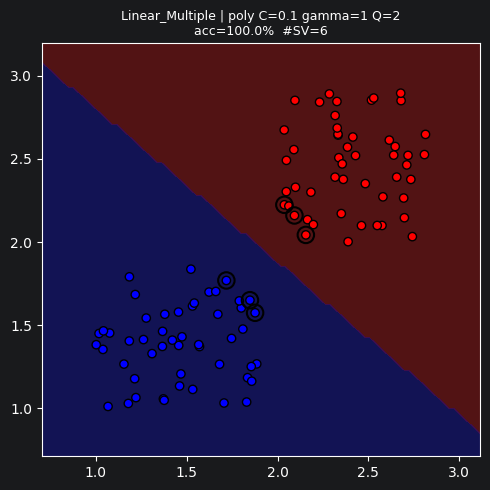

Linear_Multiple | poly C=1 gamma=1 Q=2 | acc=100.0% | #SV=3 | W0=[5.842] | status=[0]


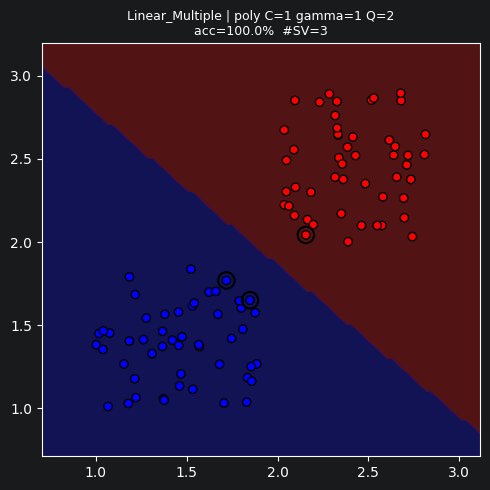

Linear_Multiple | poly C=10 gamma=1 Q=2 | acc=100.0% | #SV=3 | W0=[5.842] | status=[0]


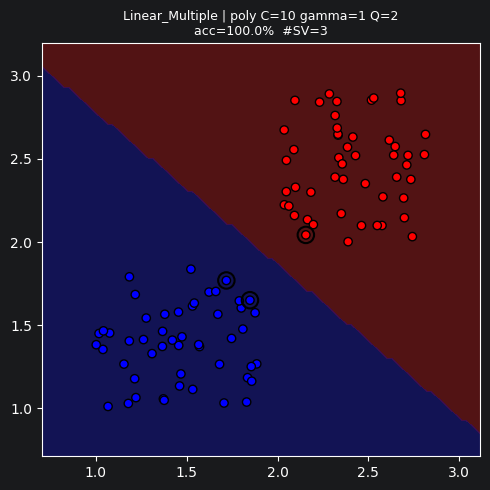

Linear_Multiple | rbf C=0.1 gamma=1 Q=2 | acc=100.0% | #SV=40 | W0=[-0.007] | status=[0]


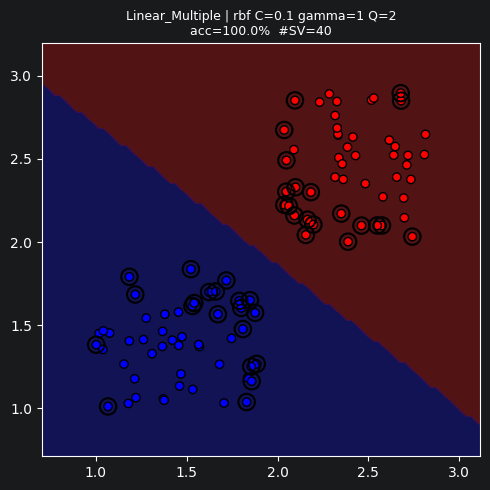

Linear_Multiple | rbf C=1 gamma=1 Q=2 | acc=100.0% | #SV=9 | W0=[0.063] | status=[0]


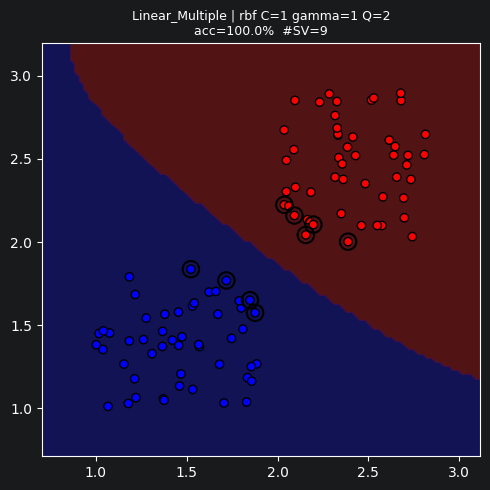

Linear_Multiple | rbf C=10 gamma=1 Q=2 | acc=100.0% | #SV=3 | W0=[0.028] | status=[0]


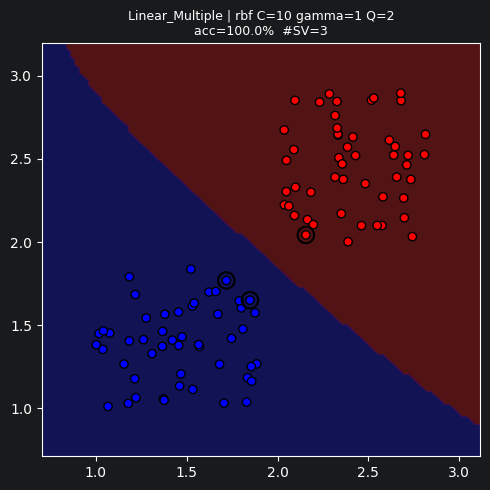

In [29]:
configs = [
    (linear, 0.1, 1, 2),
    (linear, 1, 1, 2),
    (linear, 10, 1, 2),

    (polynomial, 0.1, 1, 2),
    (polynomial, 1, 1, 2),
    (polynomial, 10, 1, 2),

    (rbf, 0.1, 1, 2),
    (rbf, 1, 1, 2),
    (rbf, 10, 1, 2)
]

run_case("Linear_Multiple", X, Y, configs)

### Exp 3 - poly degree

Linear_Multiple | poly C=10 gamma=1 Q=2 | acc=100.0% | #SV=3 | W0=[5.842] | status=[0]


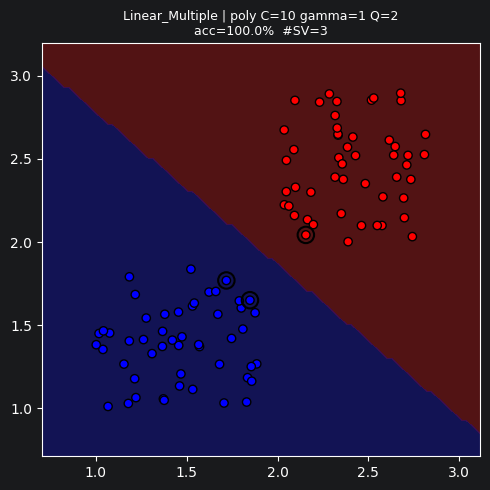

Linear_Multiple | poly C=10 gamma=1 Q=3 | acc=100.0% | #SV=2 | W0=[4.039] | status=[0]


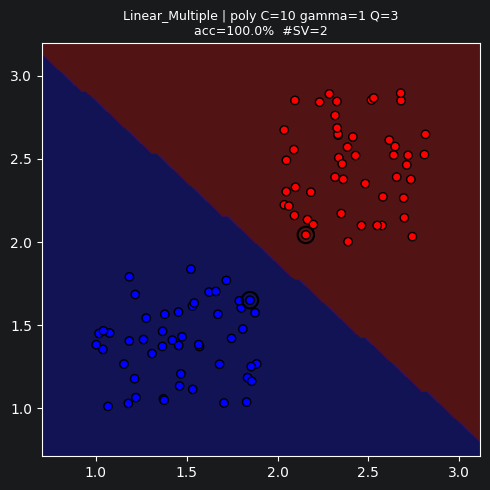

Linear_Multiple | poly C=10 gamma=1 Q=4 | acc=100.0% | #SV=2 | W0=[3.115] | status=[0]


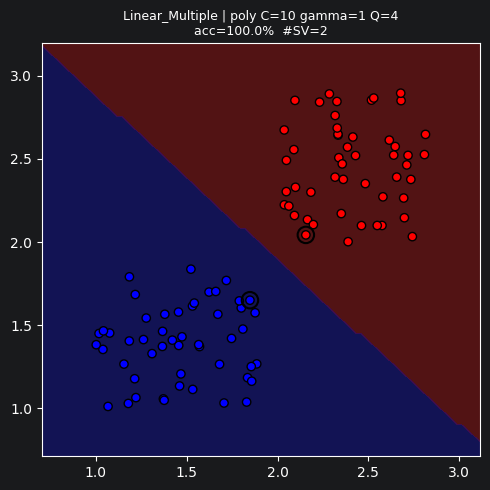

In [30]:
configs = [
    (polynomial, 10, 1, 2),
    (polynomial, 10, 1, 3),
    (polynomial, 10, 1, 4)
]

run_case("Linear_Multiple", X, Y, configs)

### Exp 4 - gamma RBF

Linear_Multiple | rbf C=10 gamma=0.01 Q=2 | acc=100.0% | #SV=26 | W0=[0.282] | status=[0]


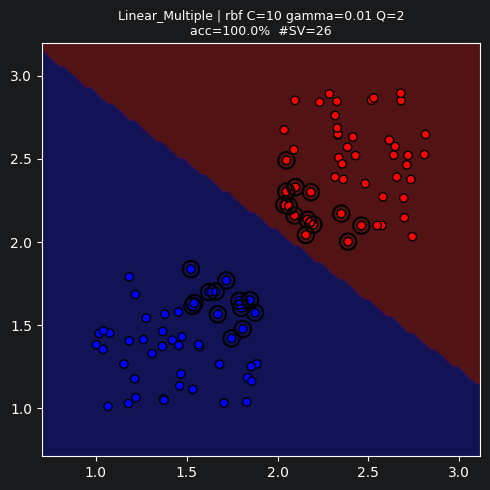

Linear_Multiple | rbf C=10 gamma=0.1 Q=2 | acc=100.0% | #SV=8 | W0=[-0.01] | status=[0]


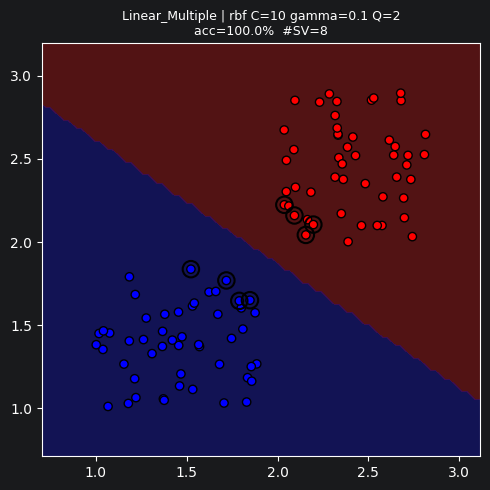

Linear_Multiple | rbf C=10 gamma=1 Q=2 | acc=100.0% | #SV=3 | W0=[0.028] | status=[0]


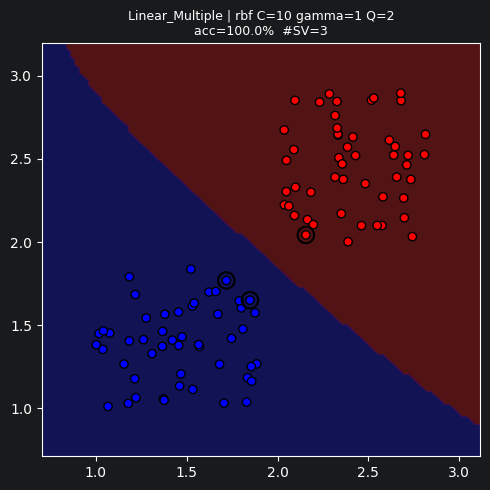

Linear_Multiple | rbf C=10 gamma=10 Q=2 | acc=100.0% | #SV=27 | W0=[0.003] | status=[0]


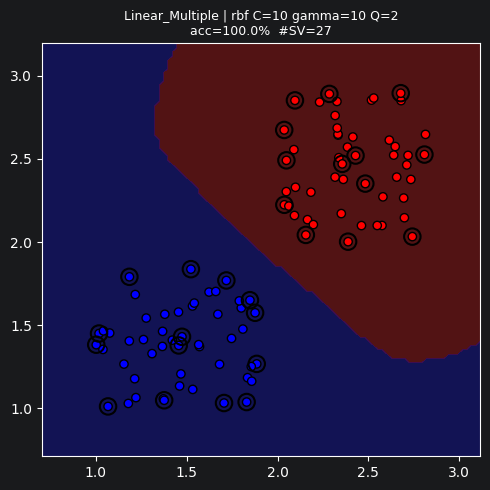

In [31]:
configs = [
    (rbf, 10, 0.01, 2),
    (rbf, 10, 0.1, 2),
    (rbf, 10, 1, 2),
    (rbf, 10, 10, 2)
]

run_case("Linear_Multiple", X, Y, configs)

## XOR :
        Linear Model    : KO
        MLP (2, 2, 1)   : OK

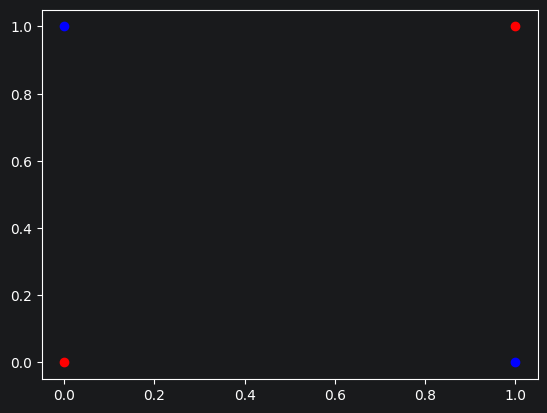

<Figure size 640x480 with 0 Axes>

In [32]:
X = np.array([[1, 0], [0, 1], [0, 0], [1, 1]])
Y = np.array([1, 1, -1, -1])
plt.scatter(X[0:2, 0], X[0:2, 1], color='blue')
plt.scatter(X[2:4,0], X[2:4,1], color='red')
plt.show()
plt.clf()

### Exp 1 - Kernel

XOR | linear C=10 gamma=1 Q=2 | acc=50.0% | #SV=4 | W0=[1.0] | status=[0]


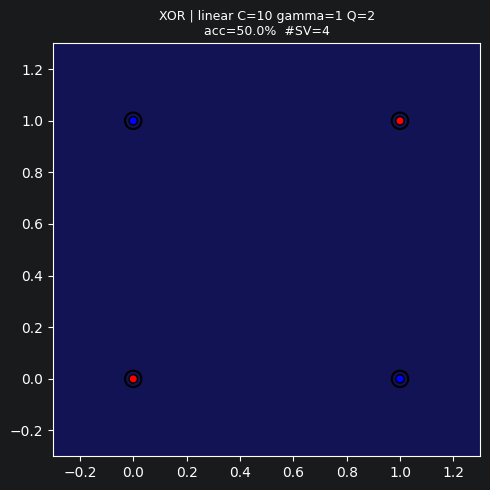

XOR | poly C=10 gamma=1 Q=2 | acc=100.0% | #SV=4 | W0=[-1.0] | status=[0]


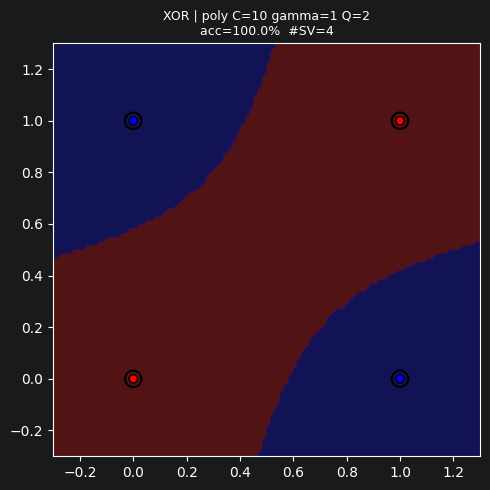

XOR | rbf C=10 gamma=1 Q=2 | acc=100.0% | #SV=4 | W0=[0.0] | status=[0]


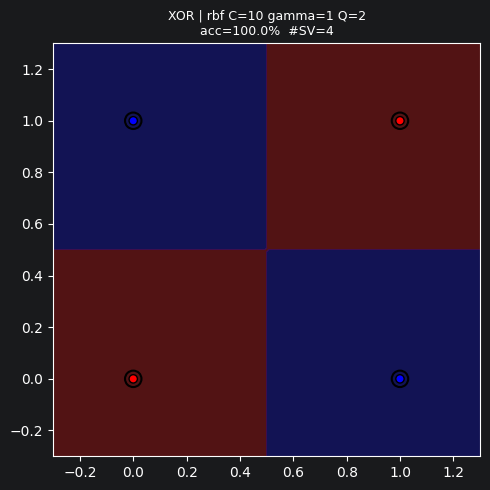

In [33]:
# Experiment 1: compare kernels
configs = [
    (linear, 10, 1, 2),
    (polynomial, 10, 1, 2),
    (rbf, 10, 1, 2)
]

run_case("XOR", X, Y, configs)

### Exp 2 - Effect of C

XOR | linear C=0.1 gamma=1 Q=2 | acc=52.2% | #SV=500 | W0=[1.0] | status=[0]


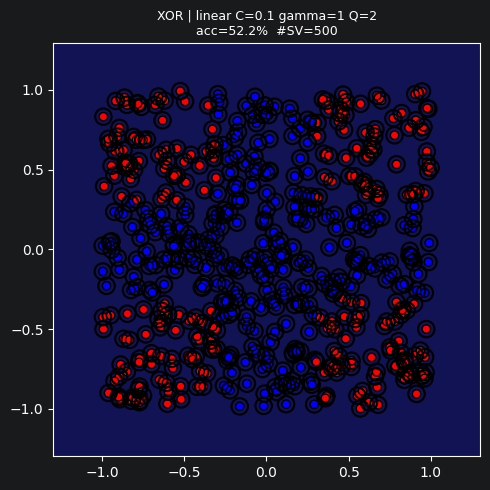

XOR | linear C=0 gamma=1 Q=2 | acc=47.8% | #SV=0 | W0=[0.0] | status=[-4]


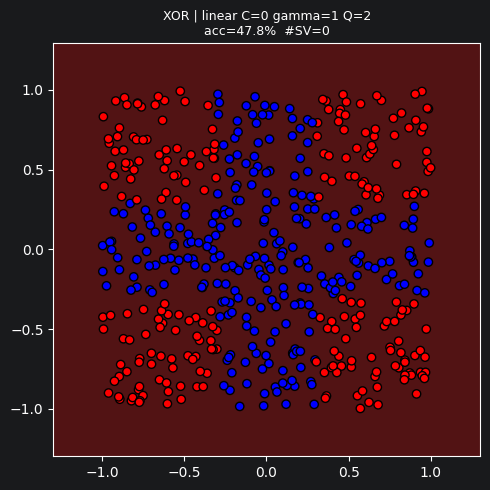

XOR | linear C=1 gamma=1 Q=2 | acc=52.2% | #SV=500 | W0=[1.0] | status=[0]


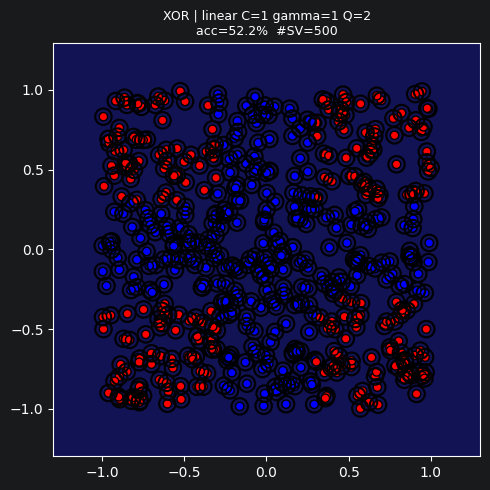

XOR | linear C=10 gamma=1 Q=2 | acc=52.2% | #SV=500 | W0=[1.0] | status=[0]


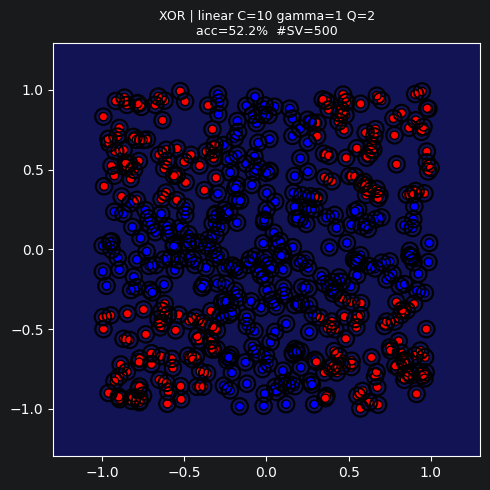

XOR | poly C=0.1 gamma=1 Q=2 | acc=73.8% | #SV=355 | W0=[1.37] | status=[0]


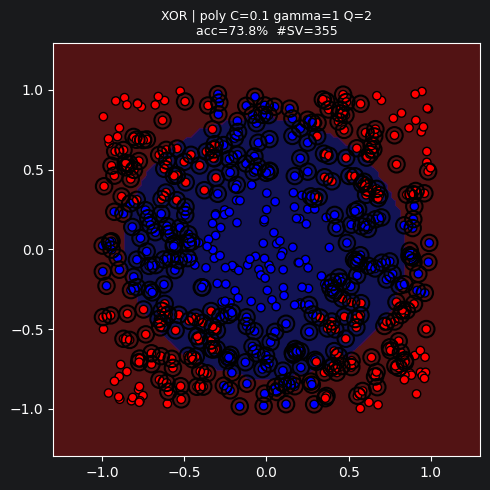

XOR | poly C=1 gamma=1 Q=2 | acc=74.2% | #SV=277 | W0=[1.787] | status=[0]


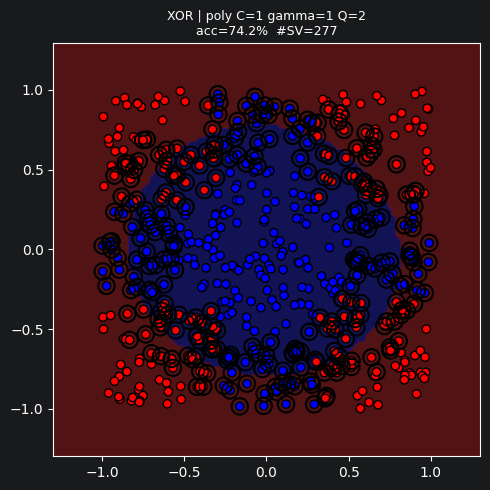

XOR | poly C=10 gamma=1 Q=2 | acc=73.6% | #SV=264 | W0=[1.932] | status=[0]


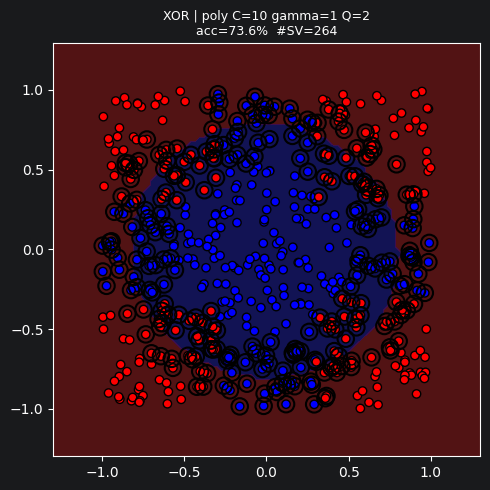

XOR | rbf C=0.1 gamma=1 Q=2 | acc=76.0% | #SV=371 | W0=[-0.937] | status=[0]


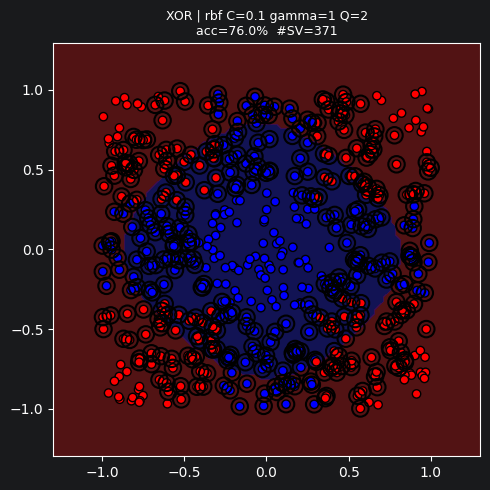

XOR | rbf C=1 gamma=1 Q=2 | acc=87.8% | #SV=272 | W0=[-0.771] | status=[0]


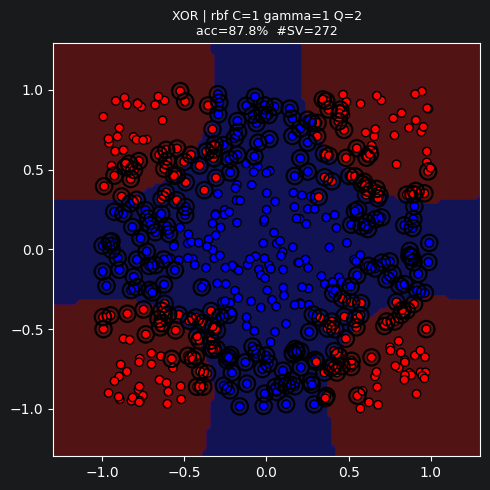

XOR | rbf C=10 gamma=1 Q=2 | acc=96.0% | #SV=154 | W0=[-0.893] | status=[0]


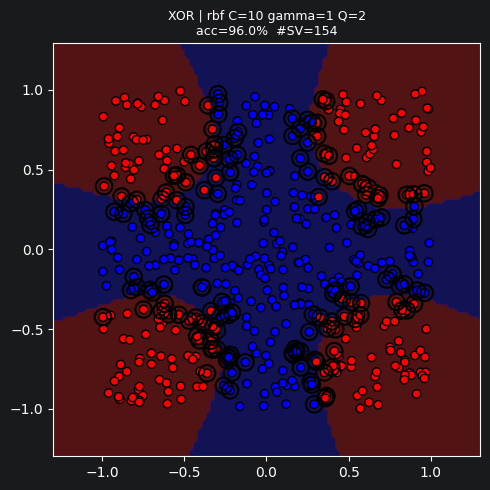

In [41]:
configs = [
    (linear, 0.1, 1, 2),
    (linear, 0, 1, 2),
    (linear, 1, 1, 2),
    (linear, 10, 1, 2),

    (polynomial, 0.1, 1, 2),
    (polynomial, 1, 1, 2),
    (polynomial, 10, 1, 2),

    (rbf, 0.1, 1, 2),
    (rbf, 1, 1, 2),
    (rbf, 10, 1, 2)
]

run_case("XOR", X, Y, configs)

### Exp 3 - Degree

XOR | poly C=10 gamma=1 Q=2 | acc=73.6% | #SV=264 | W0=[1.932] | status=[0]


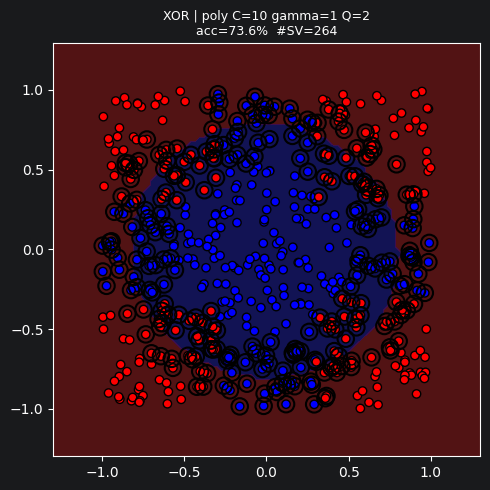

XOR | poly C=10 gamma=1 Q=4 | acc=97.6% | #SV=97 | W0=[2.12] | status=[0]


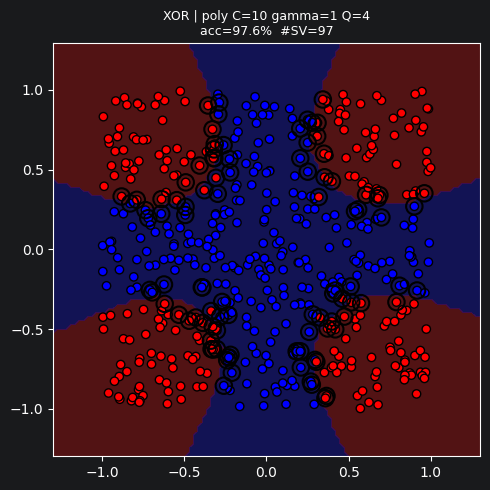

XOR | poly C=10 gamma=1 Q=6 | acc=99.2% | #SV=44 | W0=[2.491] | status=[0]


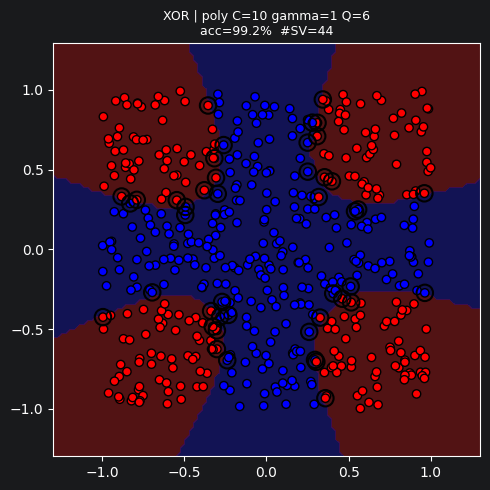

XOR | poly C=10 gamma=1 Q=8 | acc=99.4% | #SV=29 | W0=[2.441] | status=[0]


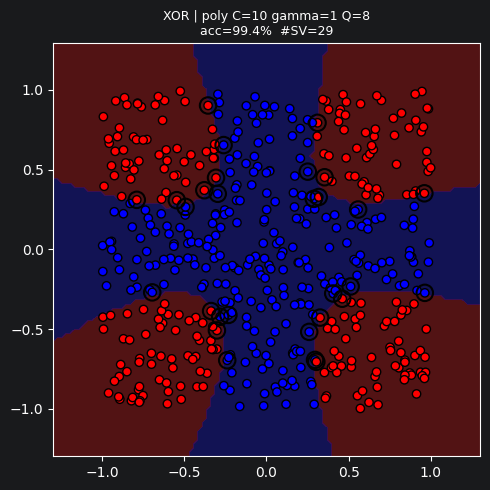

In [39]:
configs = [
    (polynomial, 10, 1, 2),
    (polynomial, 10, 1, 4),
    (polynomial, 10, 1, 6),
    (polynomial, 10, 1, 8)
]

run_case("XOR", X, Y, configs)

### Exp 4 - Effect of gamma

XOR | rbf C=10 gamma=0.01 Q=2 | acc=52.2% | #SV=480 | W0=[-11.2] | status=[0]


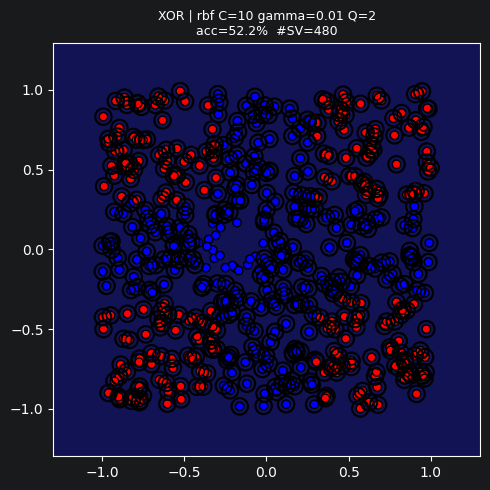

XOR | rbf C=10 gamma=0.1 Q=2 | acc=73.8% | #SV=301 | W0=[-12.249] | status=[0]


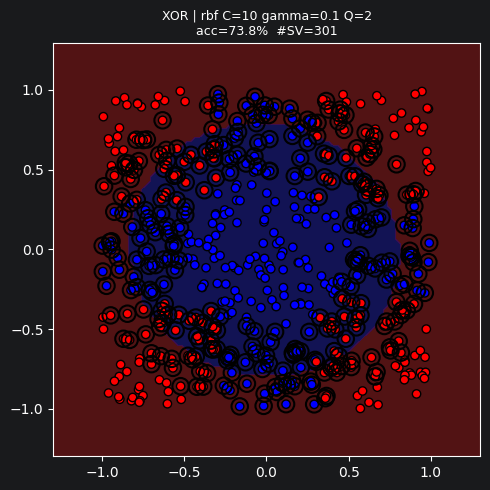

XOR | rbf C=10 gamma=1 Q=2 | acc=96.0% | #SV=154 | W0=[-0.893] | status=[0]


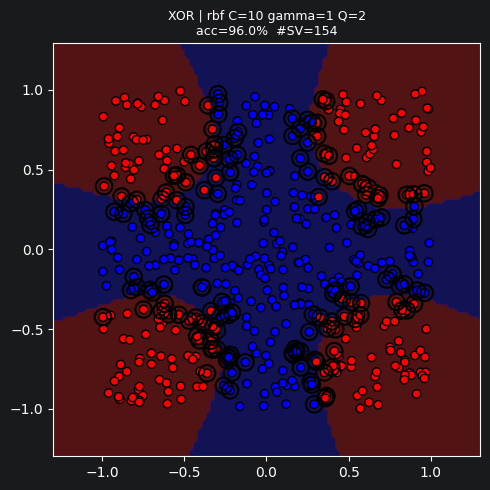

XOR | rbf C=10 gamma=10 Q=2 | acc=99.0% | #SV=68 | W0=[0.105] | status=[0]


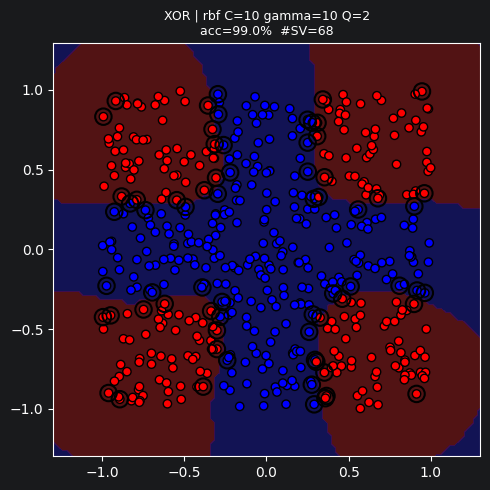

In [40]:
configs = [
    (rbf, 10, 0.01, 2),
    (rbf, 10, 0.1, 2),
    (rbf, 10, 1, 2),
    (rbf, 10, 10, 2)
]

run_case("XOR", X, Y, configs)

























































































### Cross :
        Linear Model    : KO
        MLP (2, 4, 1)   : OK

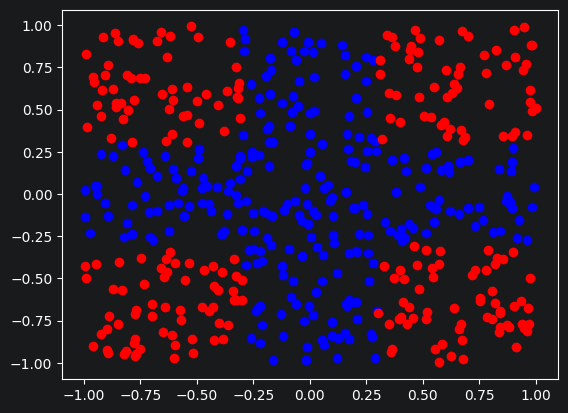

<Figure size 640x480 with 0 Axes>

In [35]:
X = np.random.random((500, 2)) * 2.0 - 1.0
Y = np.array([1 if abs(p[0]) <= 0.3 or abs(p[1]) <= 0.3 else -1 for p in X])
plt.scatter(np.array(list(map(lambda elt : elt[1], filter(lambda c: Y[c[0]] == 1, enumerate(X)))))[:,0], np.array(list(map(lambda elt : elt[1], filter(lambda c: Y[c[0]] == 1, enumerate(X)))))[:,1], color='blue')
plt.scatter(np.array(list(map(lambda elt : elt[1], filter(lambda c: Y[c[0]] == -1, enumerate(X)))))[:,0], np.array(list(map(lambda elt : elt[1], filter(lambda c: Y[c[0]] == -1, enumerate(X)))))[:,1], color='red')
plt.show()
plt.clf()

### Exp 1 - Kernel

Cross | linear C=10 gamma=1 Q=2 | acc=52.2% | #SV=500 | W0=[1.0] | status=[0]


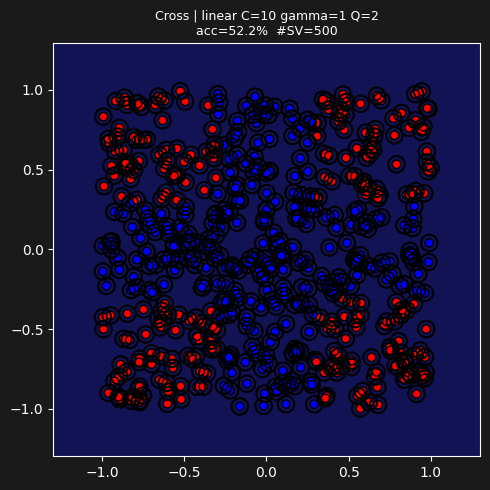

Cross | poly C=10 gamma=1 Q=2 | acc=73.6% | #SV=264 | W0=[1.932] | status=[0]


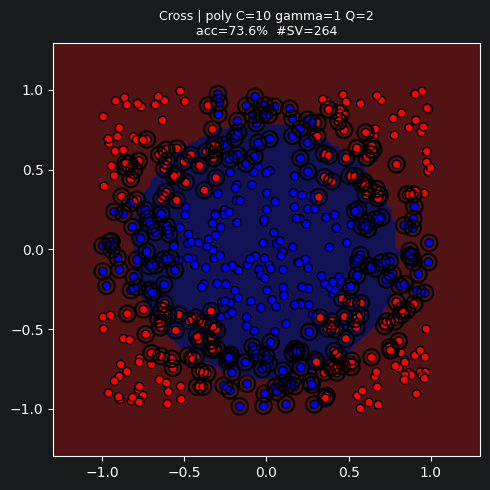

Cross | rbf C=10 gamma=1 Q=2 | acc=96.0% | #SV=154 | W0=[-0.893] | status=[0]


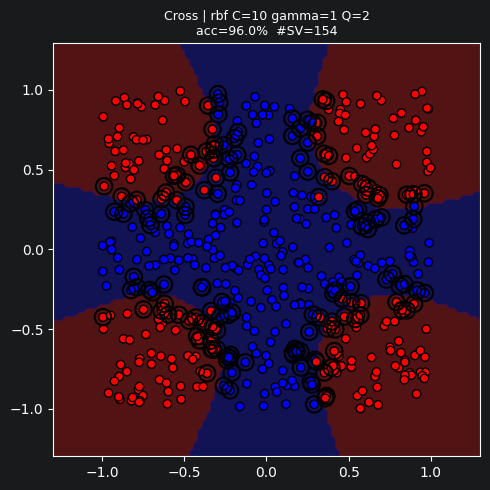

In [42]:
configs = [
    (linear, 10, 1, 2),
    (polynomial, 10, 1, 2),
    (rbf, 10, 1, 2)
]

run_case("Cross", X, Y, configs)

### Exp 2 - Effect of C

Cross | linear C=0 gamma=1 Q=2 | acc=47.8% | #SV=0 | W0=[0.0] | status=[-4]


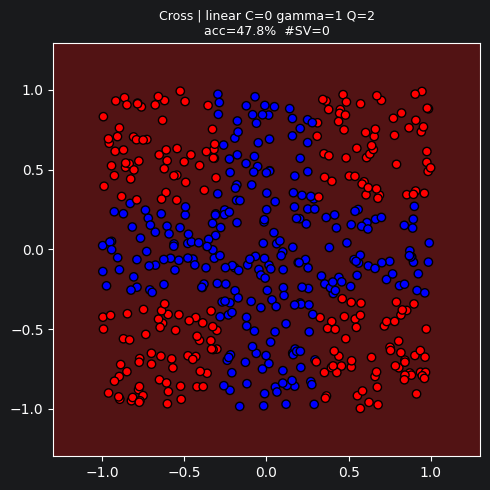

Cross | linear C=0.1 gamma=1 Q=2 | acc=52.2% | #SV=500 | W0=[1.0] | status=[0]


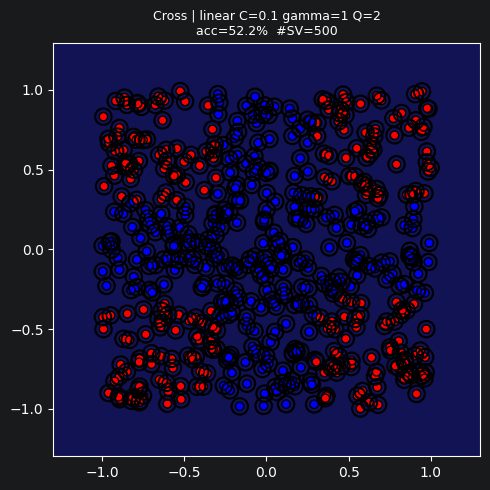

Cross | linear C=1 gamma=1 Q=2 | acc=52.2% | #SV=500 | W0=[1.0] | status=[0]


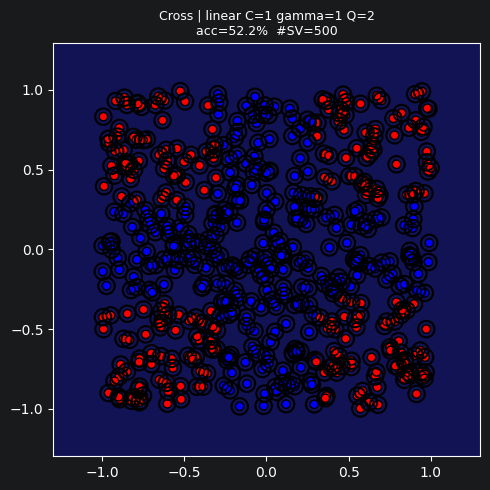

Cross | linear C=10 gamma=1 Q=2 | acc=52.2% | #SV=500 | W0=[1.0] | status=[0]


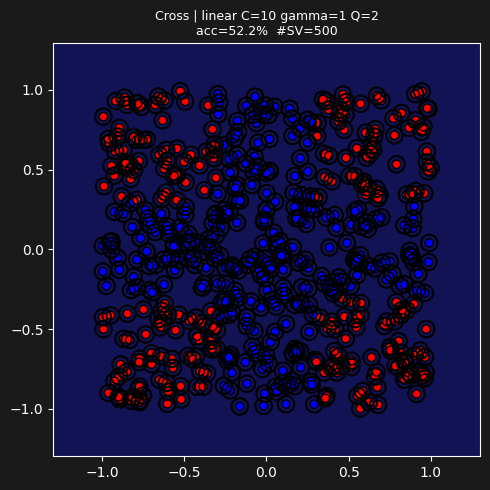

Cross | poly C=0 gamma=1 Q=2 | acc=47.8% | #SV=0 | W0=[0.0] | status=[-4]


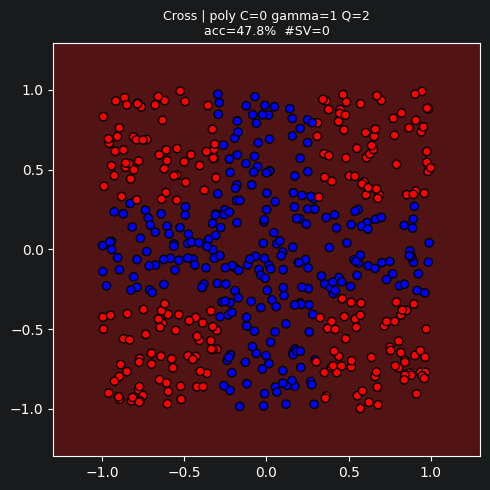

Cross | poly C=0.1 gamma=1 Q=2 | acc=73.8% | #SV=355 | W0=[1.37] | status=[0]


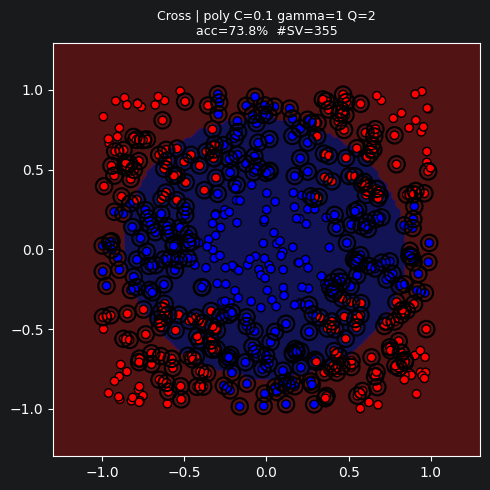

Cross | poly C=1 gamma=1 Q=2 | acc=74.2% | #SV=277 | W0=[1.787] | status=[0]


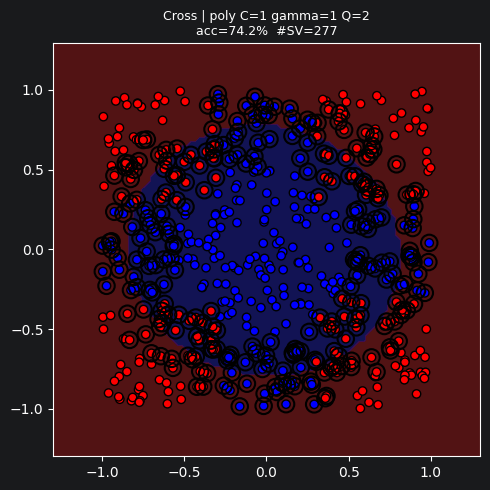

Cross | poly C=10 gamma=1 Q=2 | acc=73.6% | #SV=264 | W0=[1.932] | status=[0]


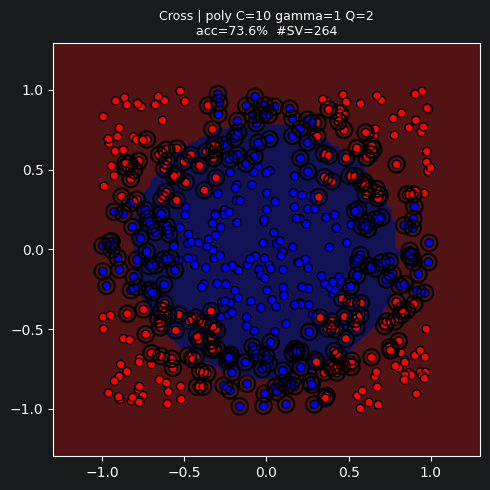

Cross | rbf C=0 gamma=1 Q=2 | acc=99.6% | #SV=16 | W0=[-60.95] | status=[1]


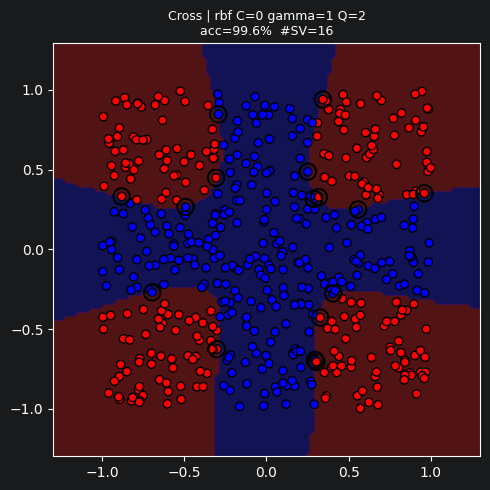

Cross | rbf C=0.1 gamma=1 Q=2 | acc=76.0% | #SV=371 | W0=[-0.937] | status=[0]


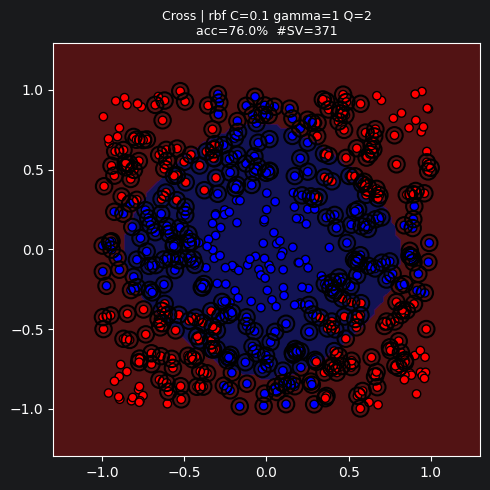

Cross | rbf C=1 gamma=1 Q=2 | acc=87.8% | #SV=272 | W0=[-0.771] | status=[0]


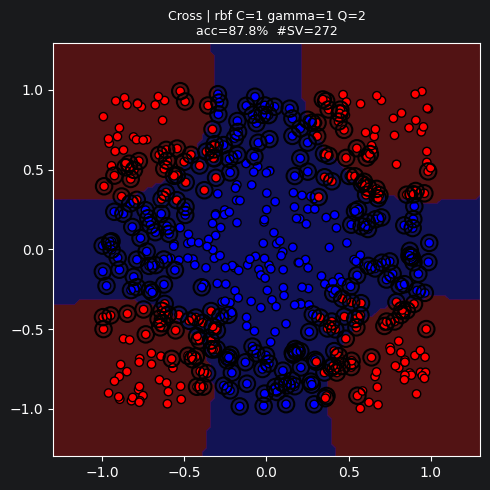

Cross | rbf C=10 gamma=1 Q=2 | acc=96.0% | #SV=154 | W0=[-0.893] | status=[0]


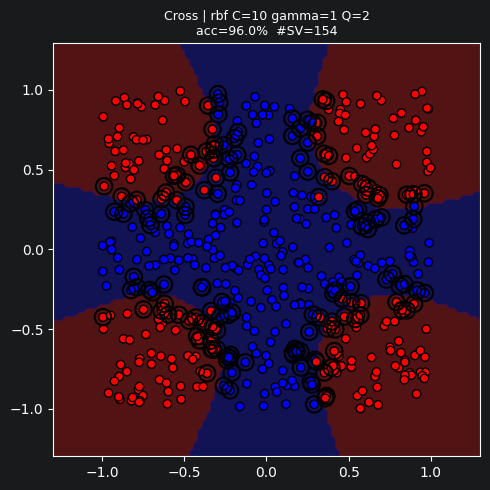

In [44]:
# Experiment 2: effect of C
configs = [
    (linear, 0, 1, 2),
    (linear, 0.1, 1, 2),
    (linear, 1, 1, 2),
    (linear, 10, 1, 2),

    (polynomial, 0, 1, 2),
    (polynomial, 0.1, 1, 2),
    (polynomial, 1, 1, 2),
    (polynomial, 10, 1, 2),

    (rbf, 0, 1, 2),
    (rbf, 0.1, 1, 2),
    (rbf, 1, 1, 2),
    (rbf, 10, 1, 2)
]

run_case("Cross", X, Y, configs)

### Exp 3 - poly degree

Cross | poly C=10 gamma=1 Q=2 | acc=73.6% | #SV=264 | W0=[1.932] | status=[0]


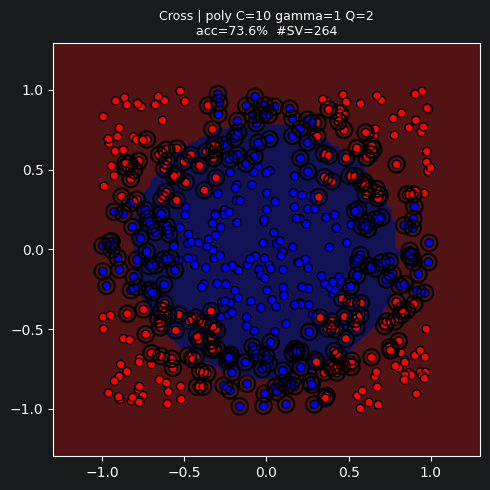

Cross | poly C=10 gamma=1 Q=3 | acc=74.4% | #SV=263 | W0=[1.938] | status=[0]


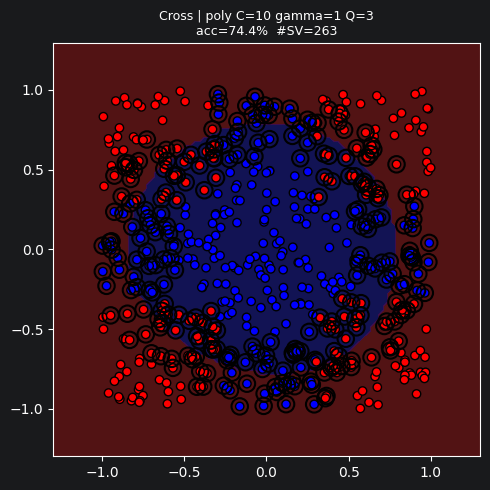

Cross | poly C=10 gamma=1 Q=4 | acc=97.6% | #SV=97 | W0=[2.12] | status=[0]


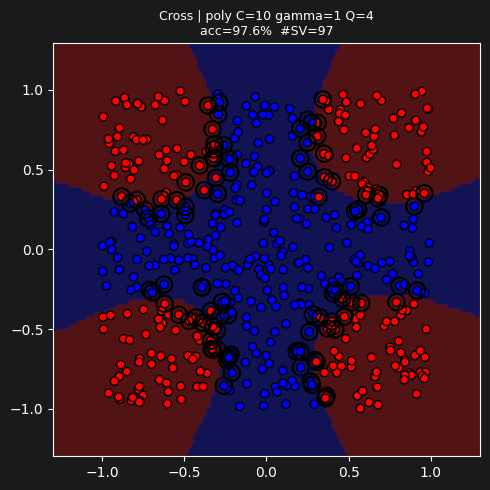

In [45]:
configs = [
    (polynomial, 10, 1, 2),
    (polynomial, 10, 1, 3),
    (polynomial, 10, 1, 4)
]

run_case("Cross", X, Y, configs)

### Exp 4 - Gamma

Cross | rbf C=10 gamma=0.01 Q=2 | acc=52.2% | #SV=480 | W0=[-11.2] | status=[0]


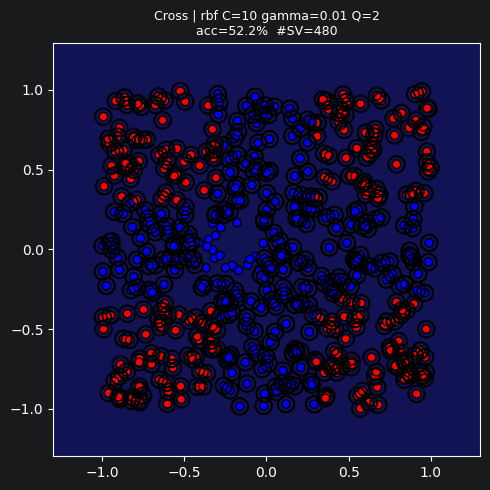

Cross | rbf C=10 gamma=0.1 Q=2 | acc=73.8% | #SV=301 | W0=[-12.249] | status=[0]


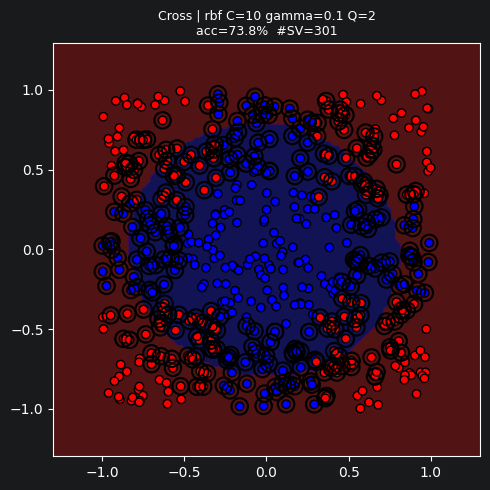

Cross | rbf C=10 gamma=1 Q=2 | acc=96.0% | #SV=154 | W0=[-0.893] | status=[0]


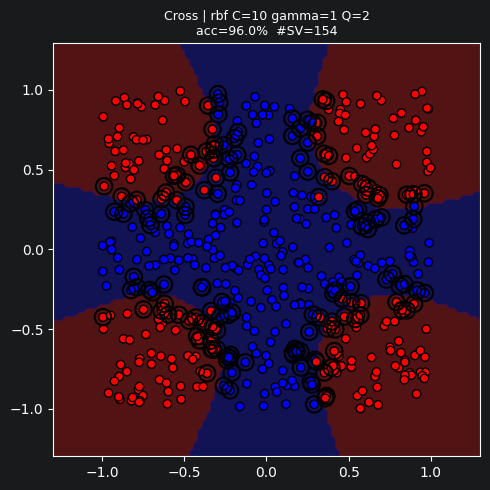

Cross | rbf C=10 gamma=10 Q=2 | acc=99.0% | #SV=68 | W0=[0.105] | status=[0]


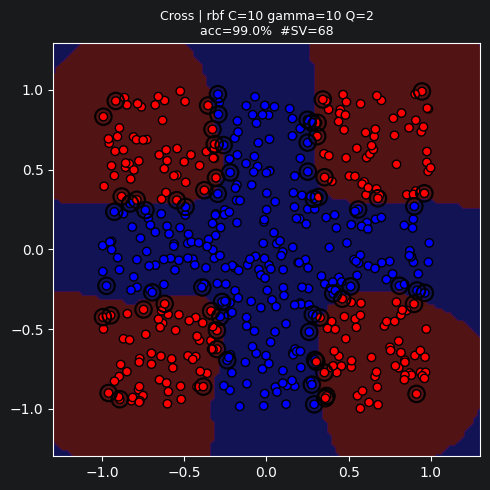

In [46]:
configs = [
    (rbf, 10, 0.01, 2),
    (rbf, 10, 0.1, 2),
    (rbf, 10, 1, 2),
    (rbf, 10, 10, 2)
]

run_case("Cross", X, Y, configs)

## Multi Linear 3 classes :
        Linear Model x3 : OK
        MLP (2, 3)      : OK

In [47]:
X = np.random.random((500, 2)) * 2.0 - 1.0
Y = np.array([[1, -1, -1] if -p[0] - p[1] - 0.5 > 0 and p[1] < 0 and p[0] - p[1] - 0.5 < 0 else
              [-1, 1, -1] if -p[0] - p[1] - 0.5 < 0 and p[1] > 0 and p[0] - p[1] - 0.5 < 0 else
              [-1, -1, 1] if -p[0] - p[1] - 0.5 < 0 and p[1] < 0 and p[0] - p[1] - 0.5 > 0 else
              [-1, -1, -1]for p in X])

X = X[[not np.all(arr == [-1, -1, -1]) for arr in Y]]
Y = Y[[not np.all(arr == [-1, -1, -1]) for arr in Y]]

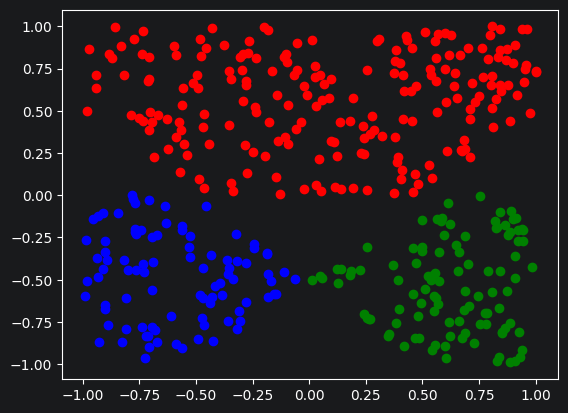

<Figure size 640x480 with 0 Axes>

In [48]:
plt.scatter(np.array(list(map(lambda elt : elt[1], filter(lambda c: Y[c[0]][0] == 1, enumerate(X)))))[:,0], np.array(list(map(lambda elt : elt[1], filter(lambda c: Y[c[0]][0] == 1, enumerate(X)))))[:,1], color='blue')
plt.scatter(np.array(list(map(lambda elt : elt[1], filter(lambda c: Y[c[0]][1] == 1, enumerate(X)))))[:,0], np.array(list(map(lambda elt : elt[1], filter(lambda c: Y[c[0]][1] == 1, enumerate(X)))))[:,1], color='red')
plt.scatter(np.array(list(map(lambda elt : elt[1], filter(lambda c: Y[c[0]][2] == 1, enumerate(X)))))[:,0], np.array(list(map(lambda elt : elt[1], filter(lambda c: Y[c[0]][2] == 1, enumerate(X)))))[:,1], color='green')
plt.show()
plt.clf()

### Exp 1 - kernel

Multi_Linear | linear C=10 gamma=1 Q=2 | acc=100.0% | #SV=73 | W0=[-3.807, 0.329, -4.523] | status=[1, 1, 1]


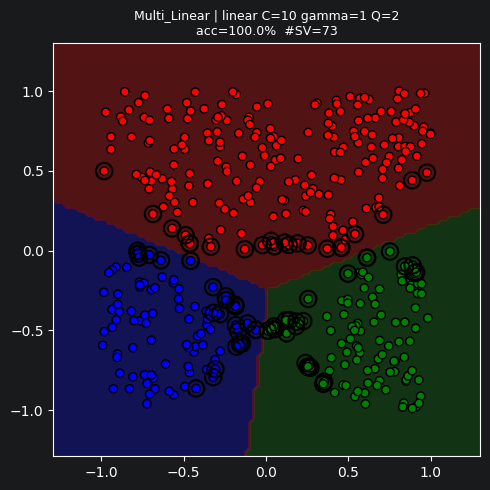

Multi_Linear | poly C=10 gamma=1 Q=2 | acc=100.0% | #SV=35 | W0=[-2.629, 1.325, -3.076] | status=[0, 0, 0]


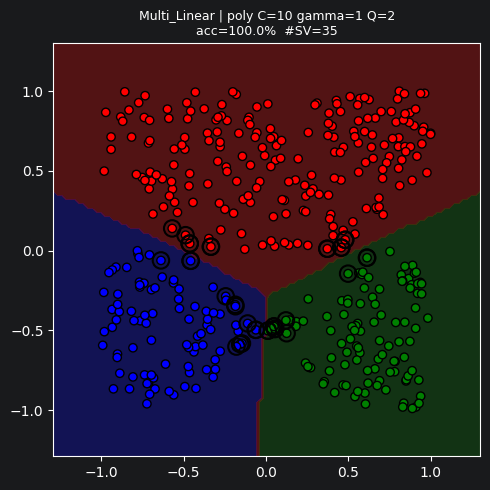

Multi_Linear | rbf C=10 gamma=1 Q=2 | acc=100.0% | #SV=40 | W0=[-1.73, -0.835, -1.433] | status=[0, 0, 0]


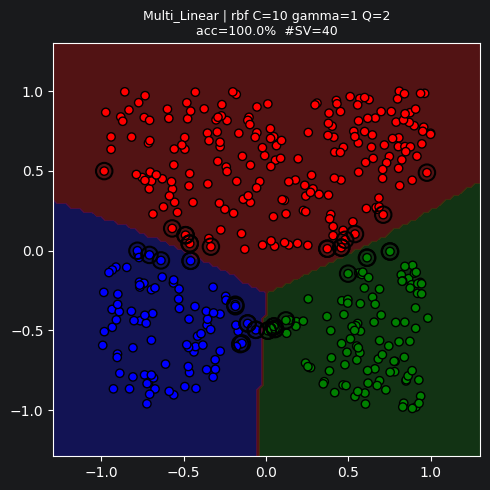

In [49]:
configs = [
    (linear, 10, 1, 2),
    (polynomial, 10, 1, 2),
    (rbf, 10, 1, 2)
]

run_case("Multi_Linear", X, Y, configs)

### Exp 2 - Effect of C

Multi_Linear | linear C=0 gamma=1 Q=2 | acc=74.5% | #SV=442 | W0=[-4.238, -408002.626, 64.9] | status=[1, 1, 1]


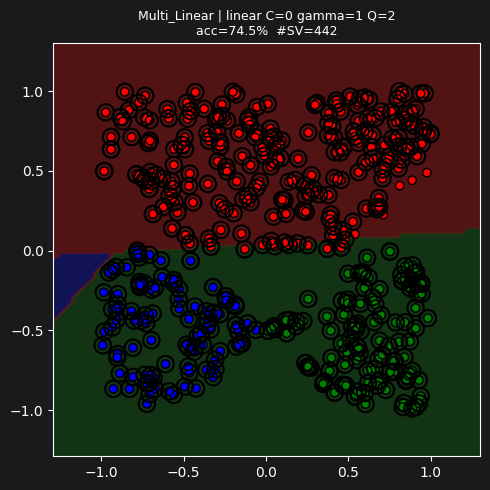

Multi_Linear | linear C=0.1 gamma=1 Q=2 | acc=100.0% | #SV=372 | W0=[-1.142, -0.093, -1.28] | status=[0, 0, 0]


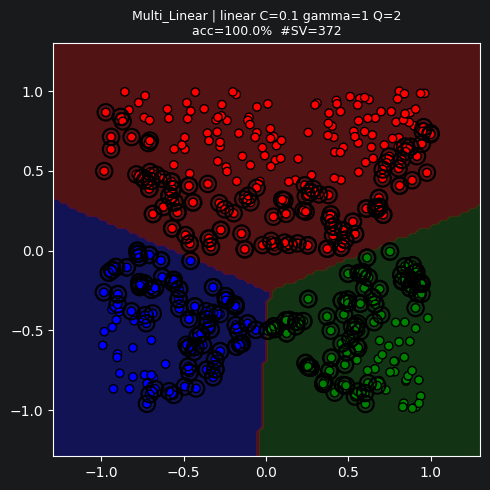

Multi_Linear | linear C=1 gamma=1 Q=2 | acc=99.8% | #SV=159 | W0=[-2.209, -0.09, -2.234] | status=[0, 0, 0]


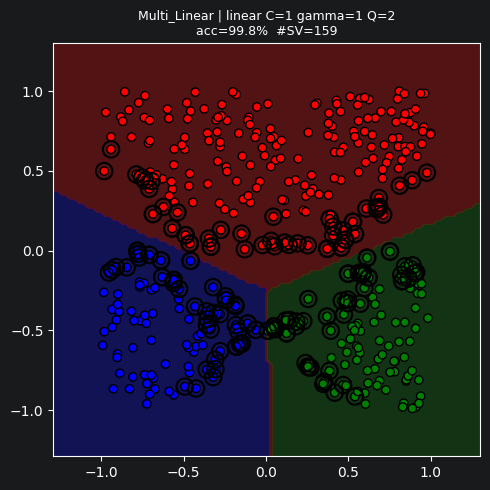

Multi_Linear | linear C=10 gamma=1 Q=2 | acc=100.0% | #SV=73 | W0=[-3.807, 0.329, -4.523] | status=[1, 1, 1]


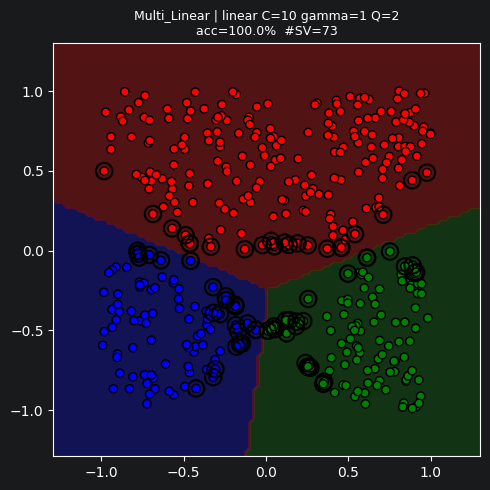

Multi_Linear | poly C=0 gamma=1 Q=2 | acc=48.5% | #SV=222 | W0=[-8.699, -10.133, 78.095] | status=[0, 1, 1]


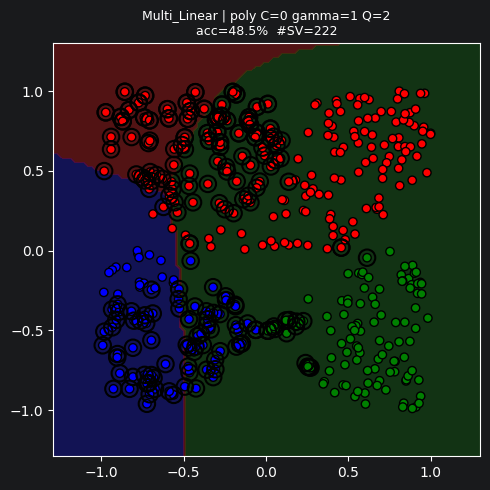

Multi_Linear | poly C=0.1 gamma=1 Q=2 | acc=99.8% | #SV=242 | W0=[-0.886, 0.272, -1.091] | status=[0, 0, 0]


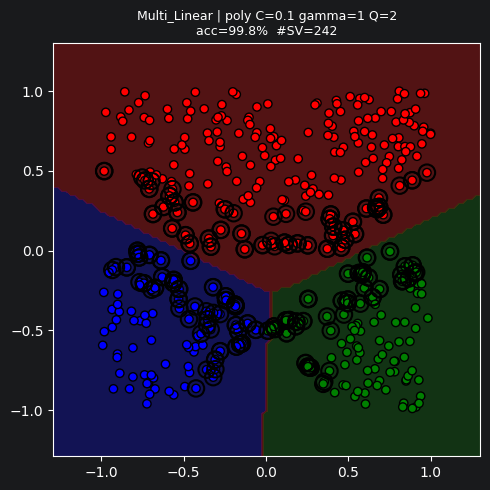

Multi_Linear | poly C=1 gamma=1 Q=2 | acc=100.0% | #SV=94 | W0=[-1.505, 0.83, -1.713] | status=[0, 0, 0]


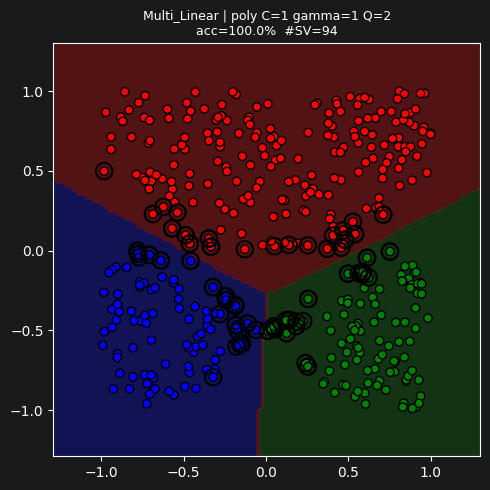

Multi_Linear | poly C=10 gamma=1 Q=2 | acc=100.0% | #SV=35 | W0=[-2.629, 1.325, -3.076] | status=[0, 0, 0]


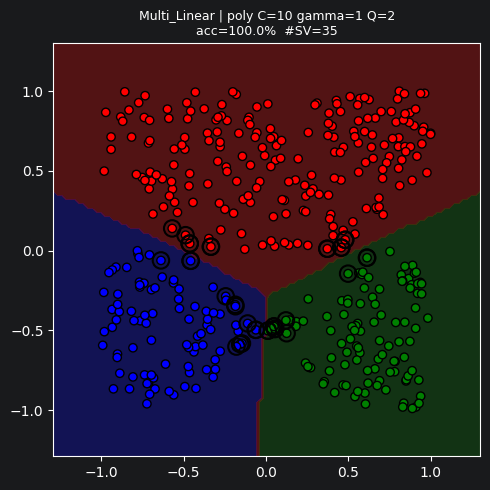

Multi_Linear | rbf C=0 gamma=1 Q=2 | acc=100.0% | #SV=13 | W0=[-4.889, -1.195, -3.729] | status=[0, 0, 0]


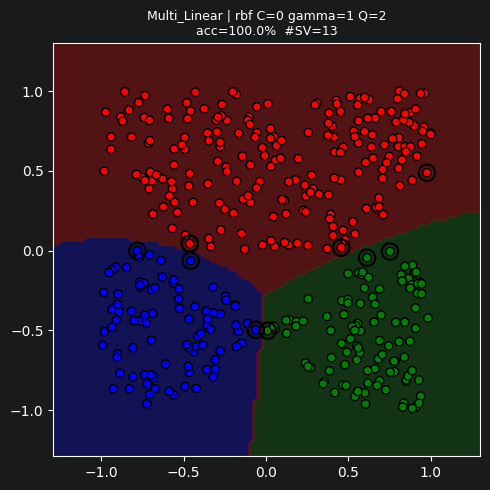

Multi_Linear | rbf C=0.1 gamma=1 Q=2 | acc=99.8% | #SV=333 | W0=[-0.614, -0.088, -0.567] | status=[0, 0, 0]


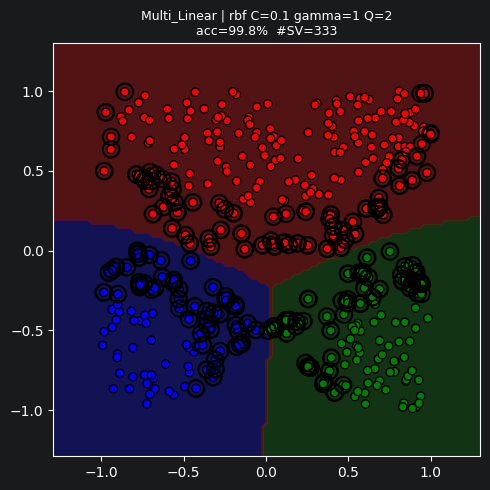

Multi_Linear | rbf C=1 gamma=1 Q=2 | acc=100.0% | #SV=110 | W0=[-0.814, -0.311, -0.829] | status=[0, 0, 0]


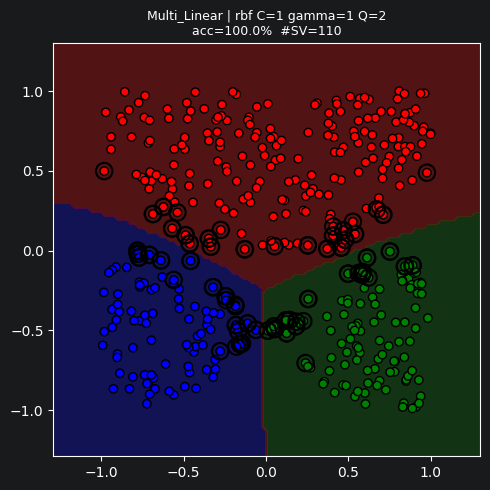

Multi_Linear | rbf C=10 gamma=1 Q=2 | acc=100.0% | #SV=40 | W0=[-1.73, -0.835, -1.433] | status=[0, 0, 0]


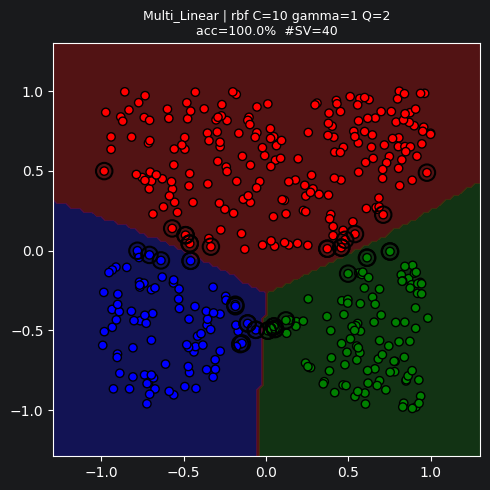

In [51]:
configs = [
    (linear, 0, 1, 2),
    (linear, 0.1, 1, 2),
    (linear, 1, 1, 2),
    (linear, 10, 1, 2),

    (polynomial, 0, 1, 2),
    (polynomial, 0.1, 1, 2),
    (polynomial, 1, 1, 2),
    (polynomial, 10, 1, 2),

    (rbf, 0, 1, 2),
    (rbf, 0.1, 1, 2),
    (rbf, 1, 1, 2),
    (rbf, 10, 1, 2)
]

run_case("Multi_Linear", X, Y, configs)

### Exp 3 - Effect of degree

Linear_Multiple | poly C=10 gamma=1 Q=2 | acc=100.0% | #SV=35 | W0=[-2.629, 1.325, -3.076] | status=[0, 0, 0]


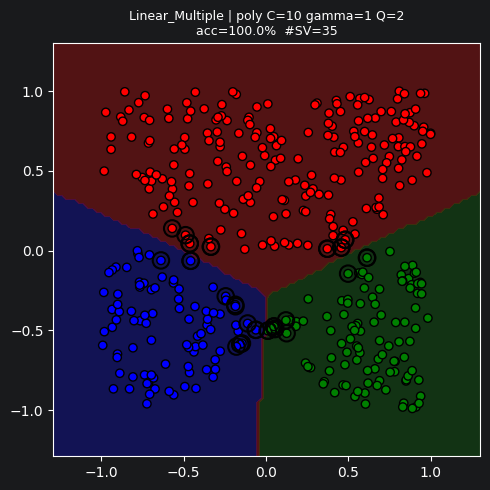

Linear_Multiple | poly C=10 gamma=1 Q=3 | acc=100.0% | #SV=28 | W0=[-2.865, 1.539, -2.821] | status=[0, 0, 0]


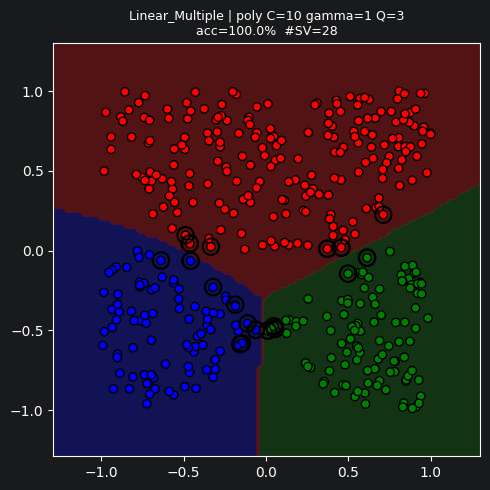

Linear_Multiple | poly C=10 gamma=1 Q=4 | acc=100.0% | #SV=20 | W0=[-2.497, 1.89, -3.078] | status=[0, 0, 0]


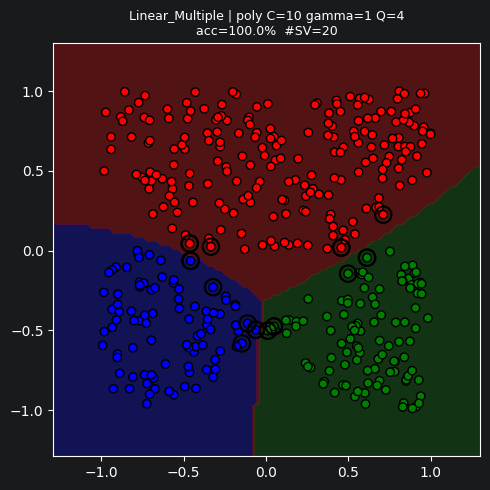

In [52]:
configs = [
    (polynomial, 10, 1, 2),
    (polynomial, 10, 1, 3),
    (polynomial, 10, 1, 4)
]

run_case("Linear_Multiple", X, Y, configs)

### Exp 4 - Effect of gamma

Linear_Multiple | rbf C=10 gamma=0.01 Q=2 | acc=100.0% | #SV=290 | W0=[-2.422, -1.943, -2.344] | status=[0, 0, 0]


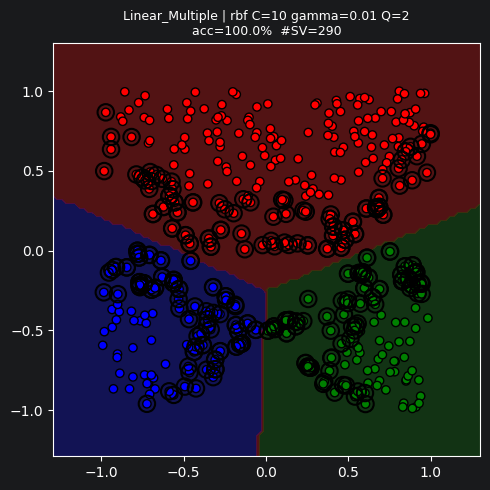

Linear_Multiple | rbf C=10 gamma=0.1 Q=2 | acc=100.0% | #SV=113 | W0=[-3.979, -4.782, -3.602] | status=[0, 0, 0]


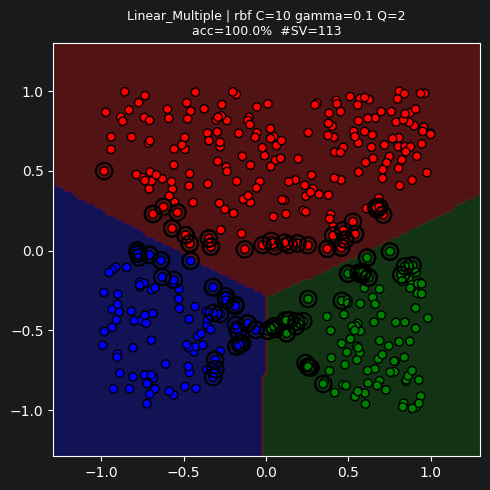

Linear_Multiple | rbf C=10 gamma=1 Q=2 | acc=100.0% | #SV=40 | W0=[-1.73, -0.835, -1.433] | status=[0, 0, 0]


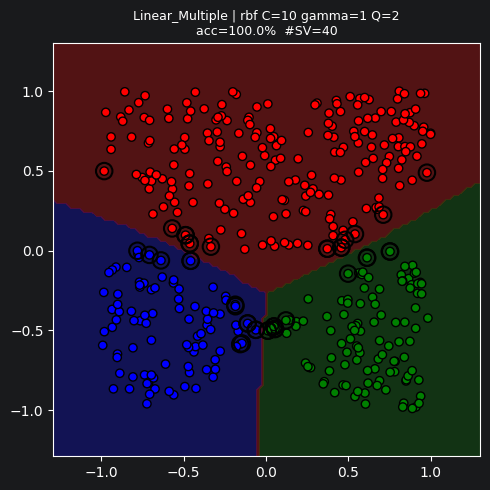

Linear_Multiple | rbf C=10 gamma=10 Q=2 | acc=100.0% | #SV=146 | W0=[-0.558, 0.039, -0.551] | status=[0, 0, 0]


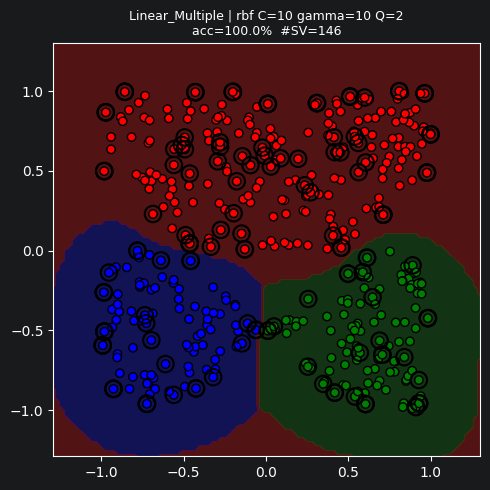

In [53]:
configs = [
    (rbf, 10, 0.01, 2),
    (rbf, 10, 0.1, 2),
    (rbf, 10, 1, 2),
    (rbf, 10, 10, 2)
]

run_case("Linear_Multiple", X, Y, configs)

# Regression

In [21]:
import ctypes

double_ptr = ctypes.POINTER(ctypes.c_double)

cpp_lib.create_svr_model.argtypes = [
    ctypes.c_int32,   # dimensions
    ctypes.c_double,  # gamma
    ctypes.c_int32,   # degree
    ctypes.c_int32    # kernel
]
cpp_lib.create_svr_model.restype = ctypes.c_void_p

cpp_lib.train_svr_model.argtypes = [
    ctypes.c_void_p,  # model
    double_ptr,       # X
    double_ptr,       # Y
    ctypes.c_int32,   # n
    ctypes.c_int32,   # d
    ctypes.c_double,  # C
    ctypes.c_double   # epsilon
]
cpp_lib.train_svr_model.restype = ctypes.c_int32

cpp_lib.predict_svr.argtypes = [
    ctypes.c_void_p,
    double_ptr
]
cpp_lib.predict_svr.restype = ctypes.c_double

cpp_lib.destroy_svr_model.argtypes = [
    ctypes.c_void_p
]
cpp_lib.destroy_svr_model.restype = None


def run_svr(X, Y, kernel=rbf, C=10.0, gamma=1.0, degree=2, epsilon=0.1, P=None):
    X = np.ascontiguousarray(X, dtype=np.float64)
    Y = np.ascontiguousarray(np.ravel(Y), dtype=np.float64)

    if P is None:
        P = X
    P = np.ascontiguousarray(P, dtype=np.float64)

    n, d = X.shape

    model = cpp_lib.create_svr_model(d, gamma, degree, kernel)

    if not model:
        raise RuntimeError("Could not create SVR model")

    try:
        status = cpp_lib.train_svr_model(
            model, ptr(X), ptr(Y), n, d, C, epsilon
        )

        if status != 0:
            raise RuntimeError(f"SVR training status: {status}")

        predictions = np.array([
            cpp_lib.predict_svr(model, ptr(np.ascontiguousarray(p)))
            for p in P
        ])

        return predictions

    finally:
        cpp_lib.destroy_svr_model(model)


In [22]:

def plot_svr(X, Y, kernel=linear, C=10, gamma=1, degree=2, epsilon=0.1):
    X = np.asarray(X, dtype=np.float64)
    Y = np.asarray(Y, dtype=np.float64).ravel()

    if X.shape[1] == 1:
        x_plot = np.linspace(X[:, 0].min() - 0.5,
                             X[:, 0].max() + 0.5, 100).reshape(-1, 1)

        y_plot = run_svr(X, Y, kernel, C, gamma, degree, epsilon, P=x_plot)
        y_pred = run_svr(X, Y, kernel, C, gamma, degree, epsilon)

        plt.figure(figsize=(7, 5))
        plt.scatter(X[:, 0], Y, color="blue", label="Donnees reelles")
        plt.plot(x_plot[:, 0], y_plot, color="red", label="Prediction SVR")

    else:
        x1, x2 = np.meshgrid(
            np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 40),
            np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 40)
        )

        points = np.c_[x1.ravel(), x2.ravel()]
        y_plot = run_svr(X, Y, kernel, C, gamma, degree, epsilon, P=points)
        y_pred = run_svr(X, Y, kernel, C, gamma, degree, epsilon)

        fig = plt.figure(figsize=(8, 6))
        ax = fig.add_subplot(111, projection="3d")
        ax.scatter(X[:, 0], X[:, 1], Y, color="blue", label="Donnees reelles")
        ax.plot_surface(x1, x2, y_plot.reshape(x1.shape),
                        color="red", alpha=0.35)
        ax.set_xlabel("X1")
        ax.set_ylabel("X2")
        ax.set_zlabel("Y")

    mse = np.mean((Y - y_pred) ** 2)
    print(f"{kernel_names[kernel]} | C={C} | epsilon={epsilon} | "
          f"gamma={gamma} | degree={degree} | MSE={mse:.6f}")

    plt.title(f"SVR - {kernel_names[kernel]} | MSE={mse:.4f}")
    plt.legend()
    plt.show()


In [23]:

configs_kernels = [
    (linear, 10, 1, 2, 0.1),
    (polynomial, 10, 1, 2, 0.1),
    (rbf, 10, 1, 2, 0.1)
]

configs_c = [
    (rbf, 0.1, 1, 2, 0.1),
    (rbf, 1, 1, 2, 0.1),
    (rbf, 10, 1, 2, 0.1)
]

configs_epsilon = [
    (rbf, 10, 1, 2, 0.01),
    (rbf, 10, 1, 2, 0.1),
    (rbf, 10, 1, 2, 0.5),
    (rbf, 10, 1, 2, 1)
]

configs_gamma = [
    (rbf, 10, 0.01, 2, 0.1),
    (rbf, 10, 0.1, 2, 0.1),
    (rbf, 10, 1, 2, 0.1),
    (rbf, 10, 10, 2, 0.1)
]

configs_degree = [
    (polynomial, 10, 1, 2, 0.1),
    (polynomial, 10, 1, 3, 0.1),
    (polynomial, 10, 1, 4, 0.1)
]

def run_case_svr(case, X, Y, configs):
    for kernel, C, gamma, degree, epsilon in configs:
        print(f"\n{case}")
        plot_svr(X, Y, kernel, C, gamma, degree, epsilon)



## Linear Simple 2D :
        Linear Model : OK
        MLP (1, 1)   : OK

In [24]:
X = np.array([
      [1],
      [2]
])
Y = np.array([
      2,
      3
])

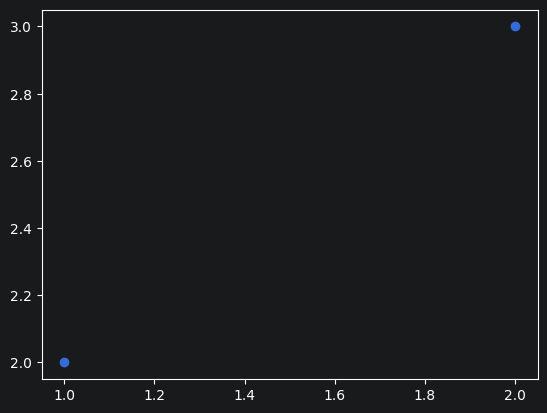

<Figure size 640x480 with 0 Axes>

In [25]:
plt.scatter(X,Y)
plt.show()
plt.clf()

linear | C=10 | epsilon=0.01 | gamma=1 | degree=2 | MSE=0.000100


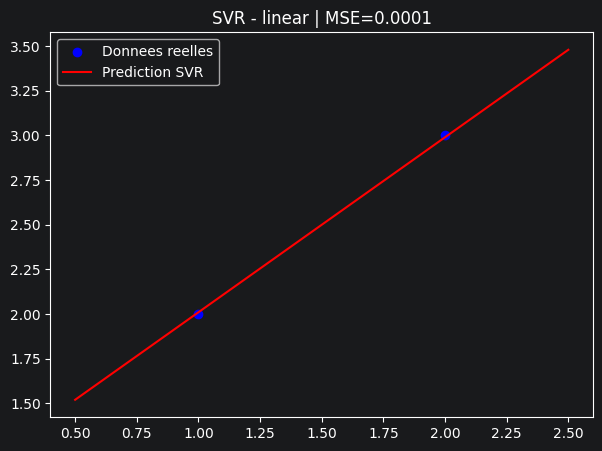

In [26]:
plot_svr(X, Y, kernel=linear, C=10, epsilon=0.01)

linear | C=10 | epsilon=0.01 | gamma=1 | degree=2 | MSE=0.000100


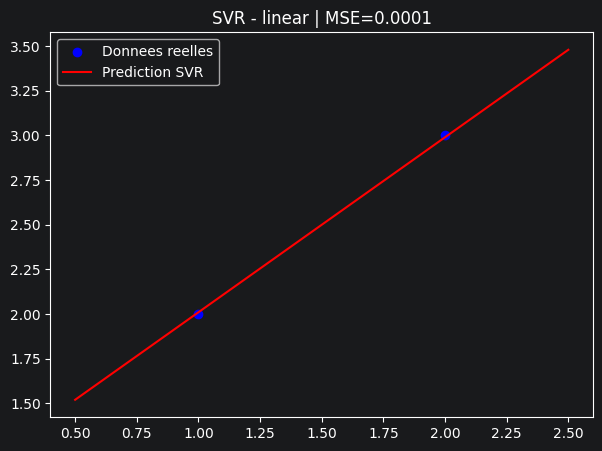

In [27]:
plot_svr(X, Y, kernel=linear, C=10, epsilon=0.01)

## Non Linear Simple 2D :
        Linear Model    : OK
        MLP (1, ?, 1)   : OK

In [28]:
X = np.array([
      [1],
      [2],
      [3]
])
Y = np.array([
      2,
      3,
      2.5
])

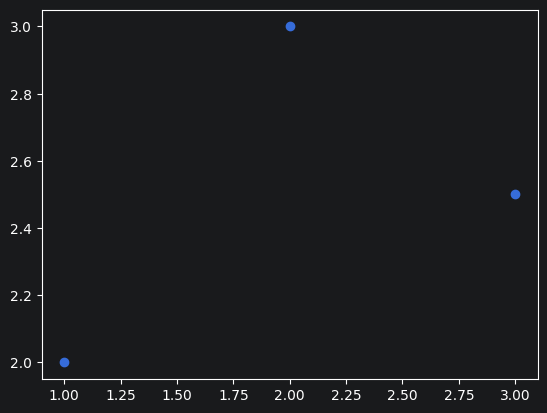

<Figure size 640x480 with 0 Axes>

In [29]:
plt.scatter(X,Y)
plt.show()
plt.clf()


Linear Simple 2D
linear | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.147500


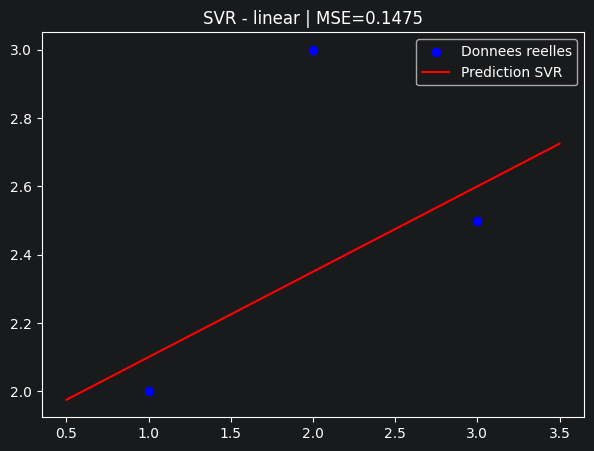


Linear Simple 2D
poly | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.010000


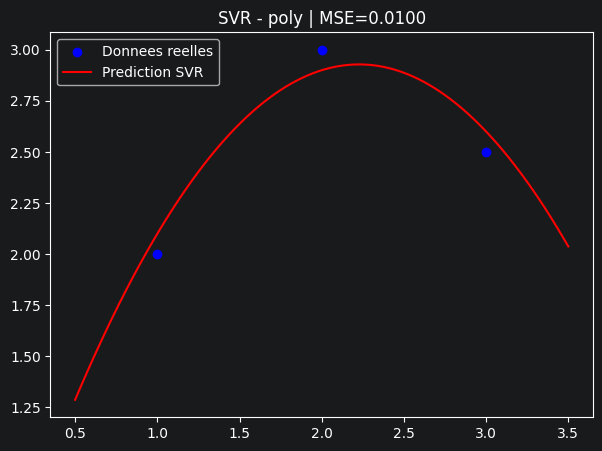


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.010000


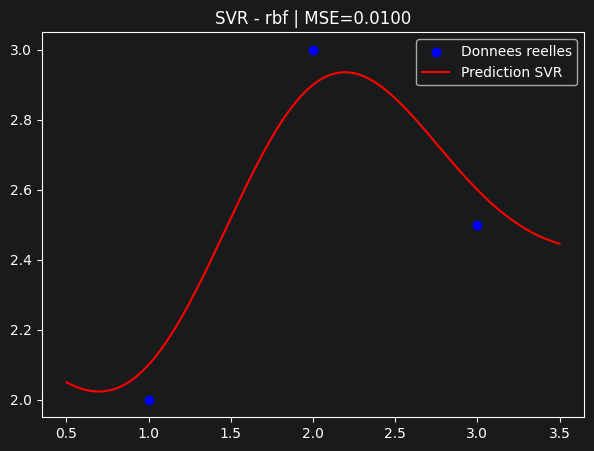


Linear Simple 2D
rbf | C=0.1 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.128004


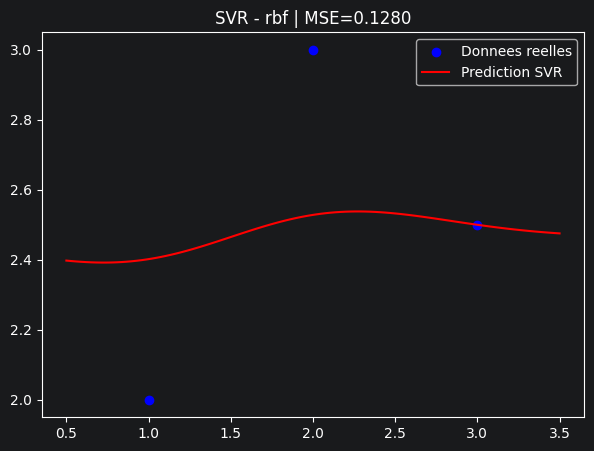


Linear Simple 2D
rbf | C=1 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.010000


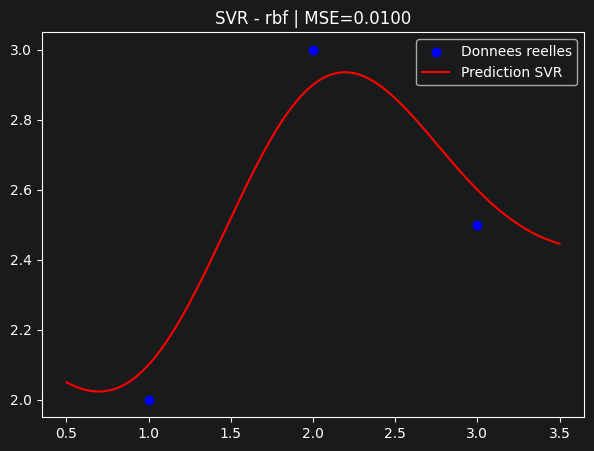


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.010000


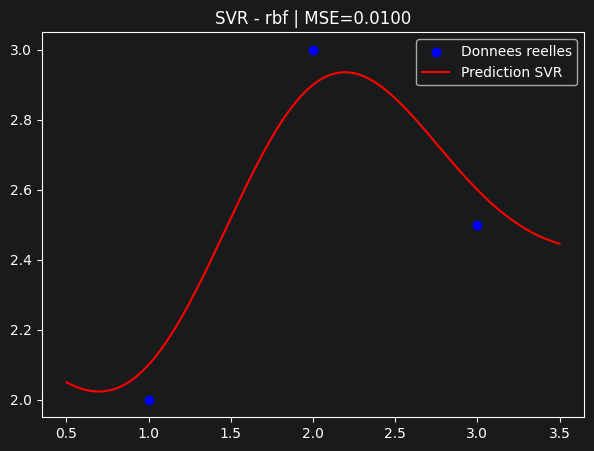


Linear Simple 2D
rbf | C=10 | epsilon=0.01 | gamma=1 | degree=2 | MSE=0.000100


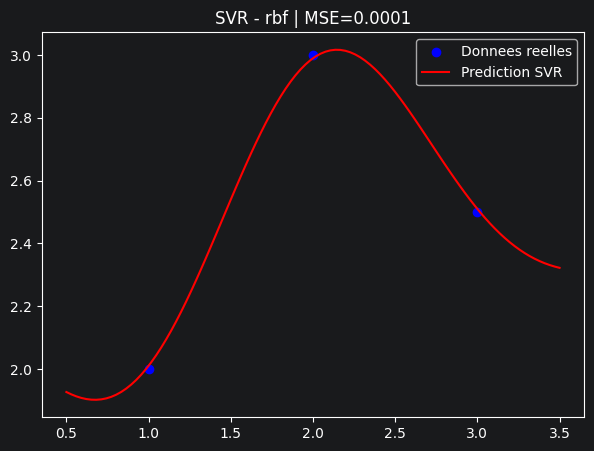


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.010000


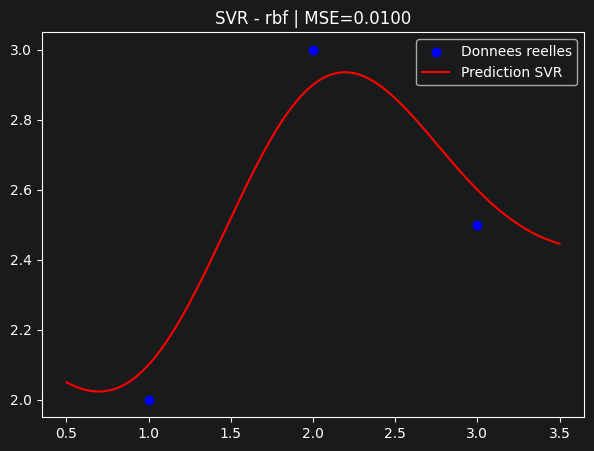


Linear Simple 2D
rbf | C=10 | epsilon=0.5 | gamma=1 | degree=2 | MSE=0.166667


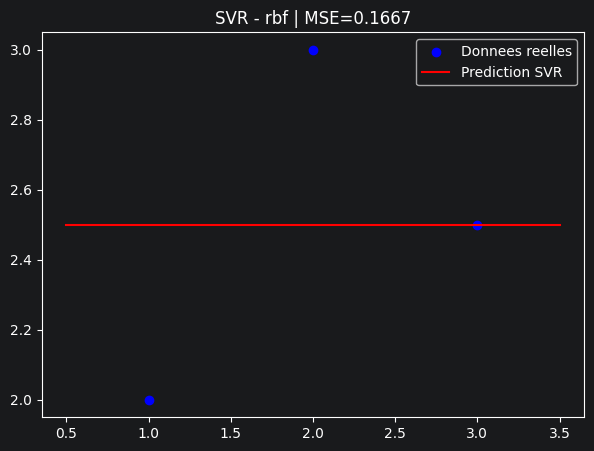


Linear Simple 2D
rbf | C=10 | epsilon=1 | gamma=1 | degree=2 | MSE=0.166667


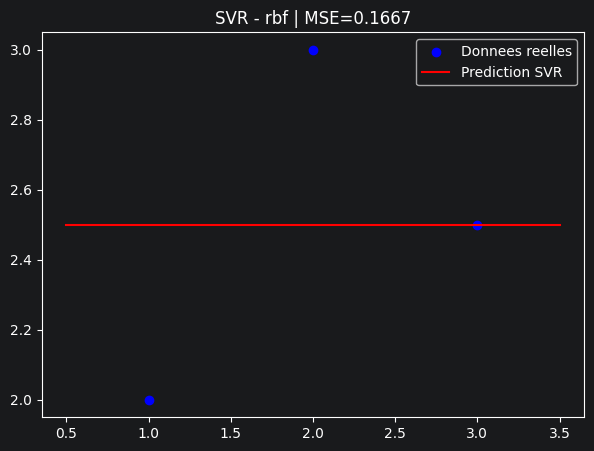


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=0.01 | degree=2 | MSE=0.148165


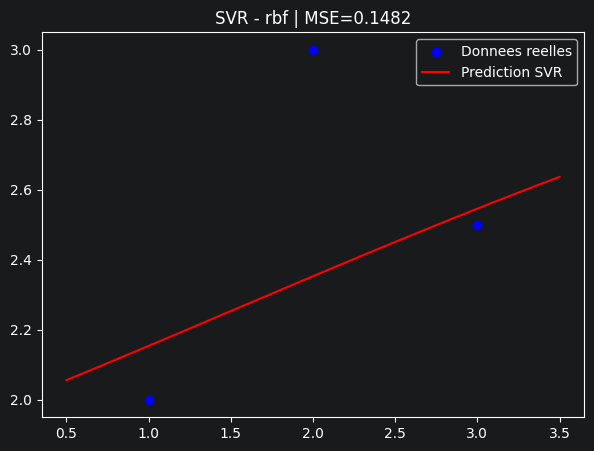


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=0.1 | degree=2 | MSE=0.058714


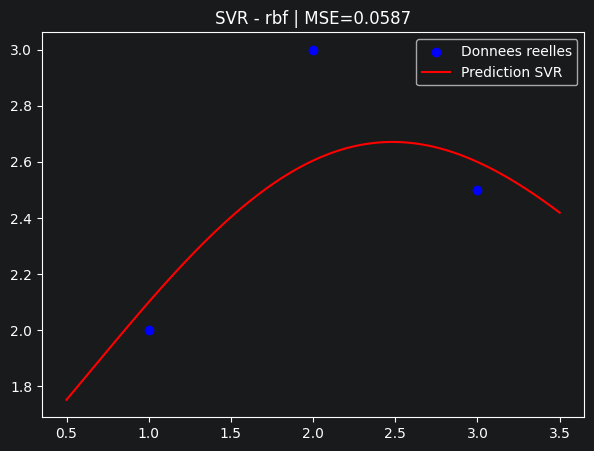


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.010000


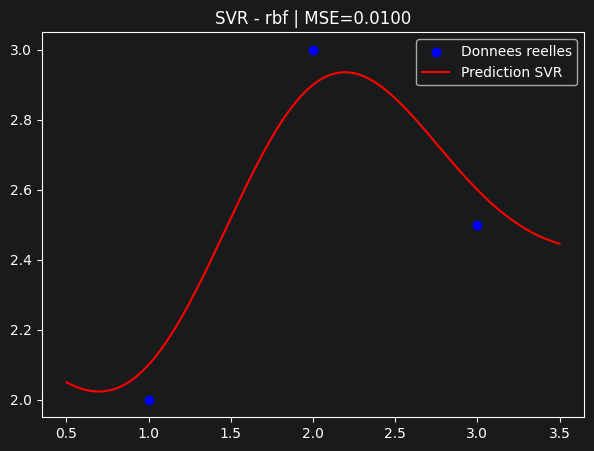


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=10 | degree=2 | MSE=0.006667


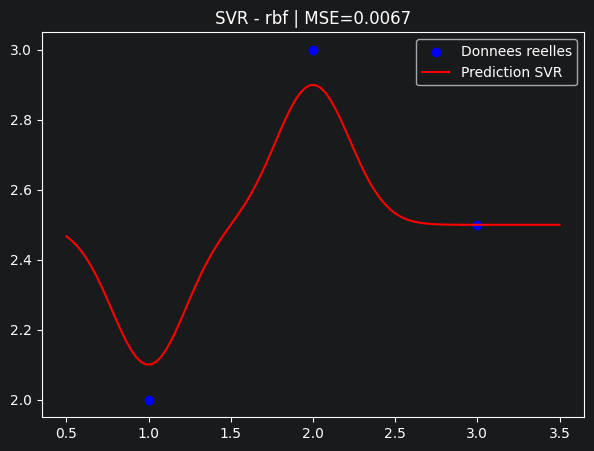


Linear Simple 2D
poly | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.010000


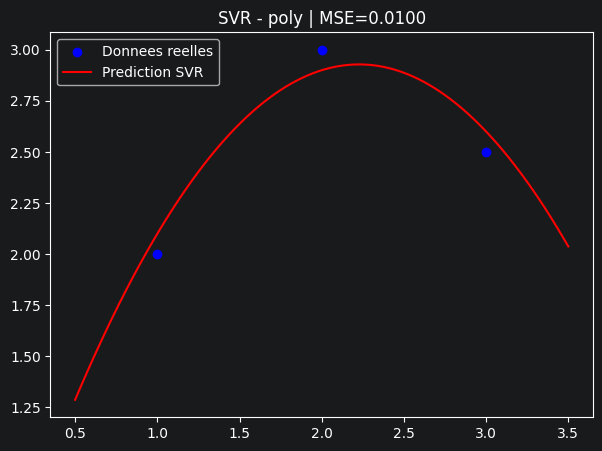


Linear Simple 2D
poly | C=10 | epsilon=0.1 | gamma=1 | degree=3 | MSE=0.010000


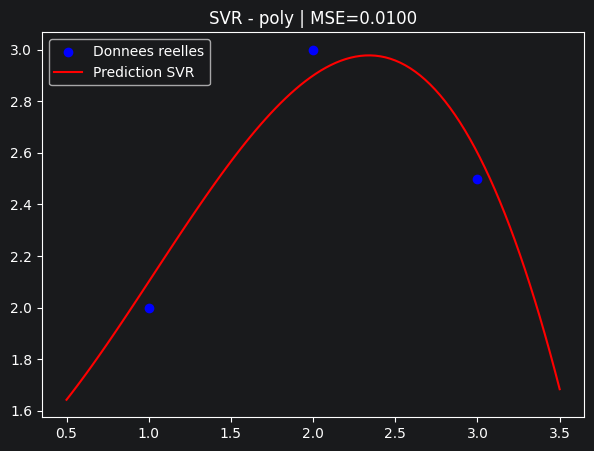


Linear Simple 2D
poly | C=10 | epsilon=0.1 | gamma=1 | degree=4 | MSE=0.010000


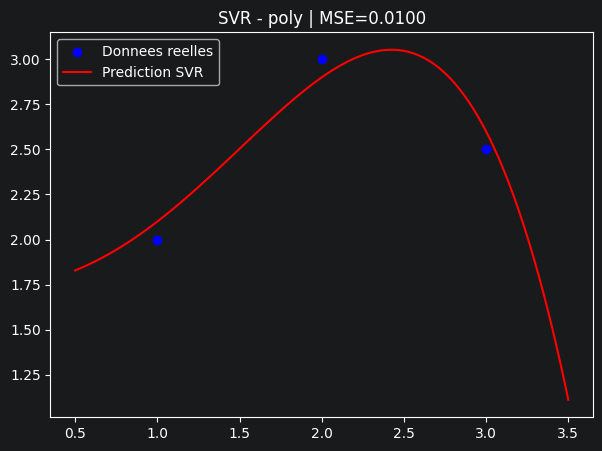

In [31]:
run_case_svr("Linear Simple 2D", X, Y, configs_kernels)
run_case_svr("Linear Simple 2D", X, Y, configs_c)
run_case_svr("Linear Simple 2D", X, Y, configs_epsilon)
run_case_svr("Linear Simple 2D", X, Y, configs_gamma)
run_case_svr("Linear Simple 2D", X, Y, configs_degree)


### Linear Simple 3D :
        Linear Model    : OK
        MLP (2, 1)      : OK

In [32]:
X = np.array([
      [1, 1],
      [2, 2],
      [3, 1]
])
Y = np.array([
      2,
      3,
      2.5
])

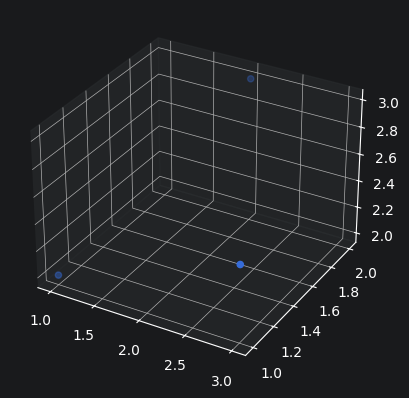

In [33]:
fig, ax = plt.subplots(subplot_kw={'projection': '3d'})
ax.scatter(X[:, 0], X[:, 1], Y)
plt.show()


Linear Simple 2D
linear | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.010000


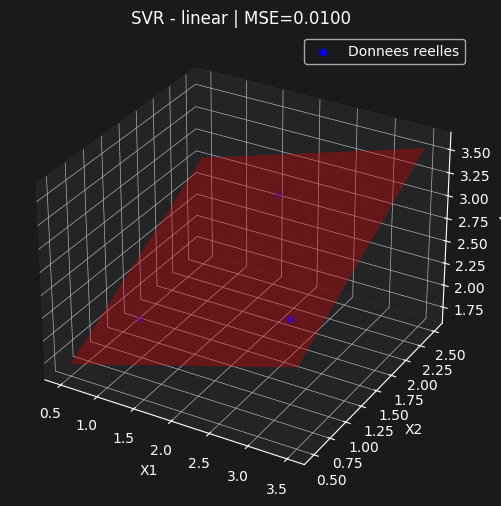


Linear Simple 2D
poly | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.010000


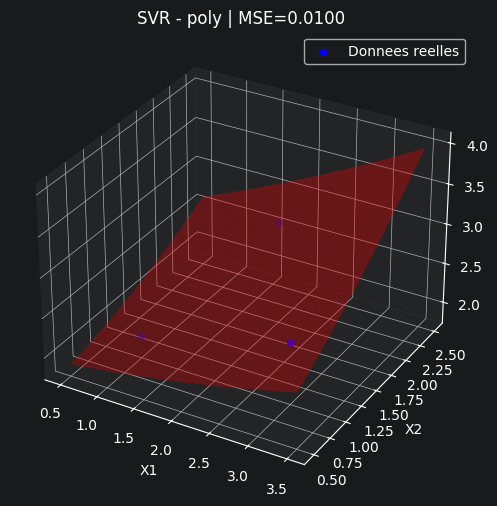


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.007644


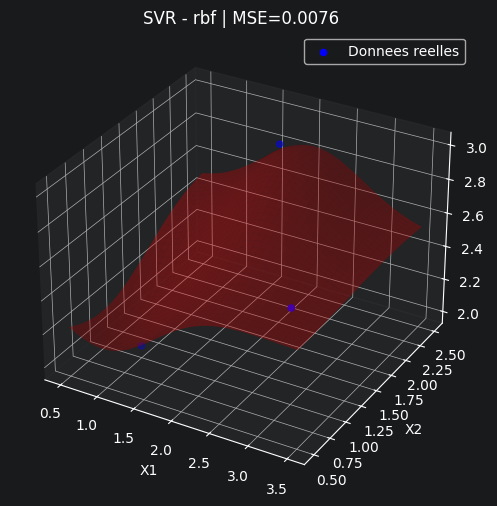


Linear Simple 2D
rbf | C=0.1 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.114098


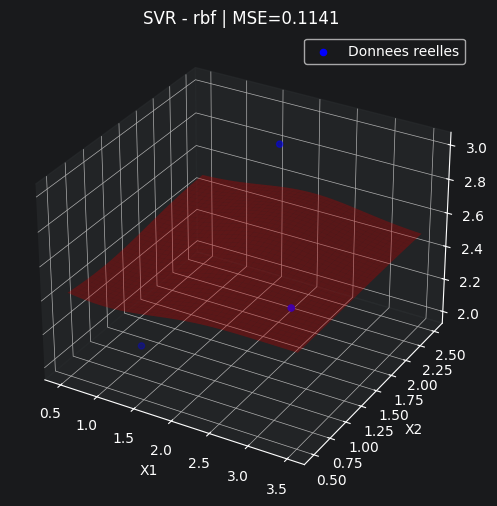


Linear Simple 2D
rbf | C=1 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.007644


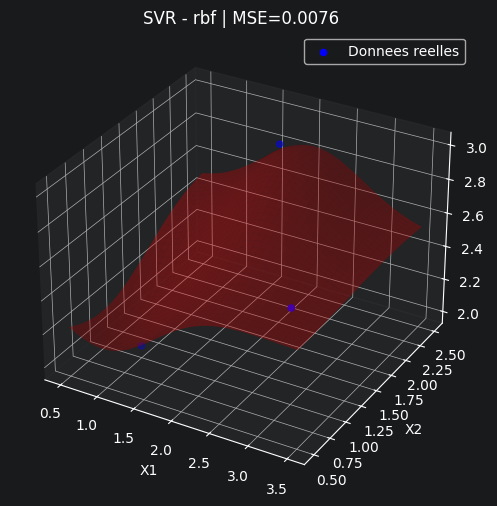


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.007644


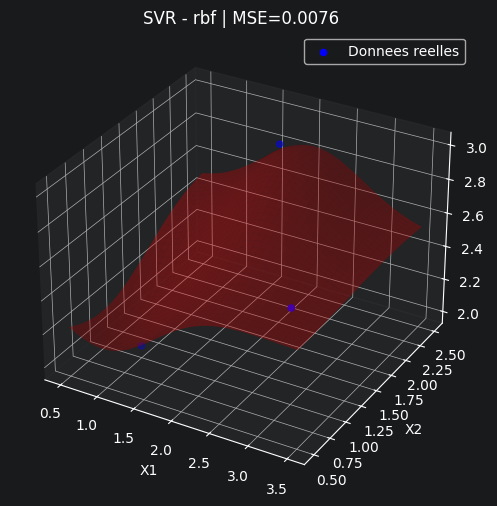


Linear Simple 2D
rbf | C=10 | epsilon=0.01 | gamma=1 | degree=2 | MSE=0.000100


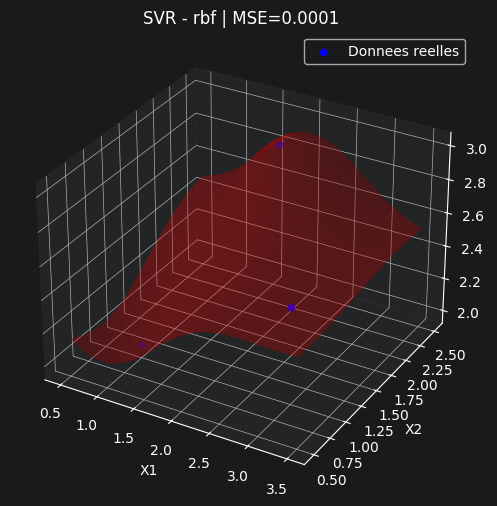


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.007644


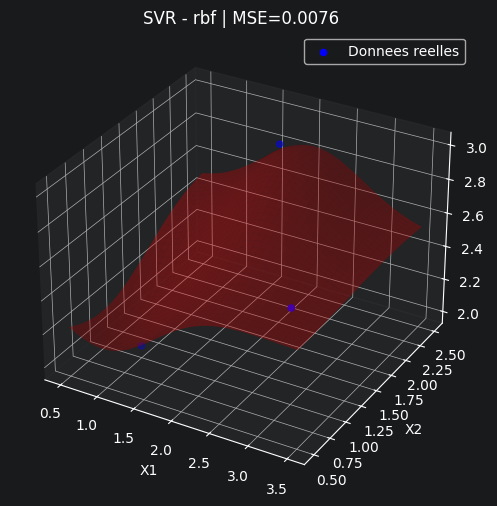


Linear Simple 2D
rbf | C=10 | epsilon=0.5 | gamma=1 | degree=2 | MSE=0.166667


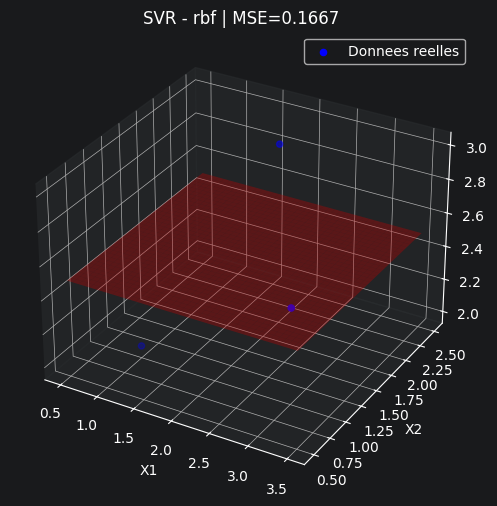


Linear Simple 2D
rbf | C=10 | epsilon=1 | gamma=1 | degree=2 | MSE=0.166667


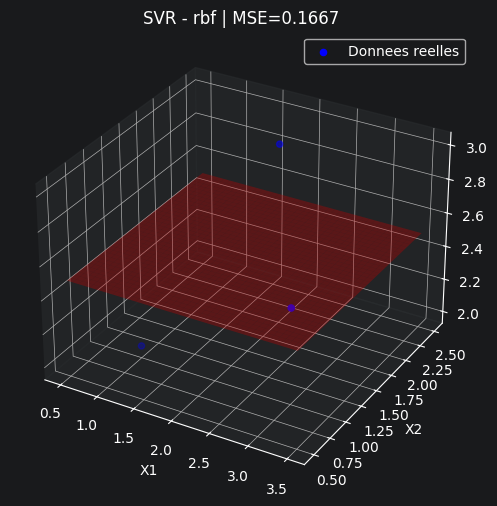


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=0.01 | degree=2 | MSE=0.076115


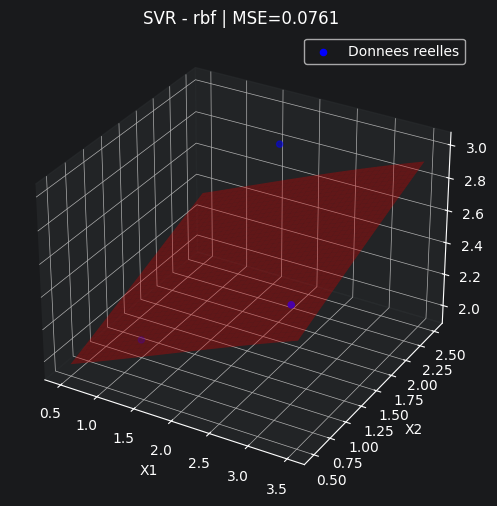


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=0.1 | degree=2 | MSE=0.010000


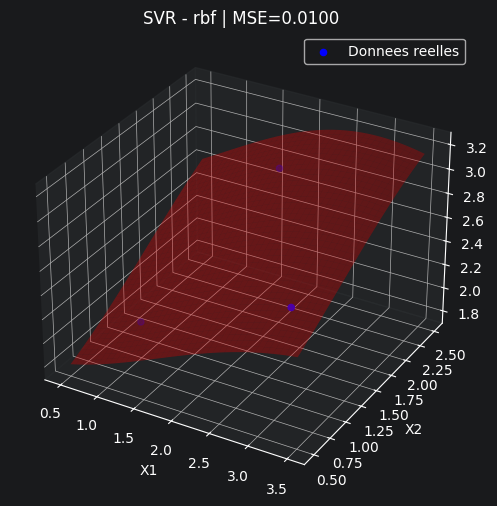


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.007644


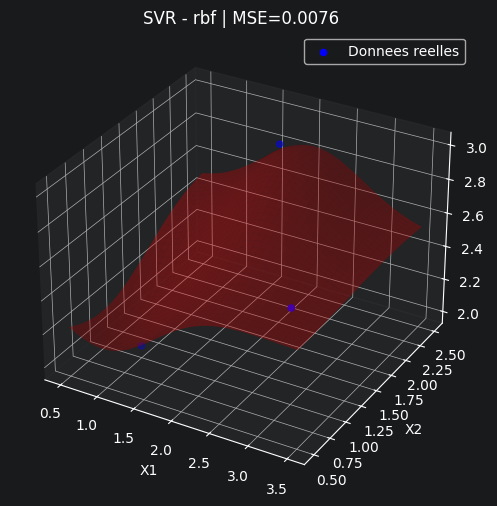


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=10 | degree=2 | MSE=0.006667


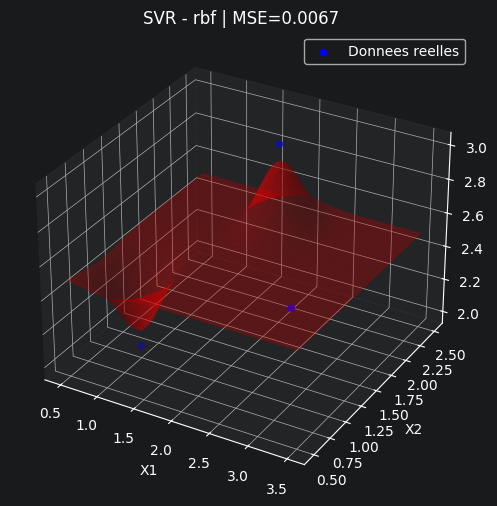


Linear Simple 2D
poly | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.010000


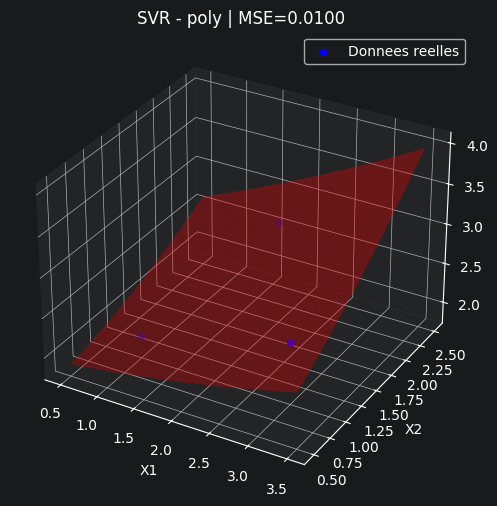


Linear Simple 2D
poly | C=10 | epsilon=0.1 | gamma=1 | degree=3 | MSE=0.010000


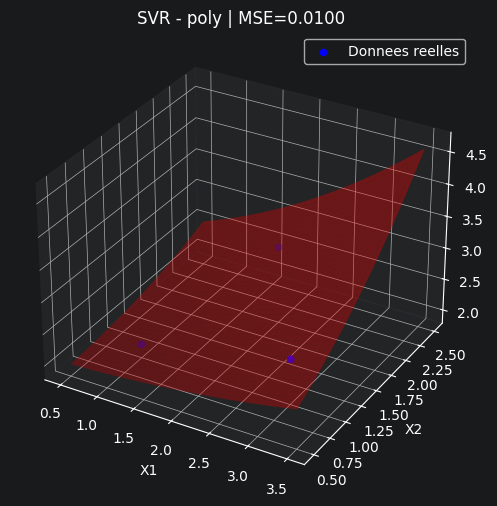


Linear Simple 2D
poly | C=10 | epsilon=0.1 | gamma=1 | degree=4 | MSE=0.010000


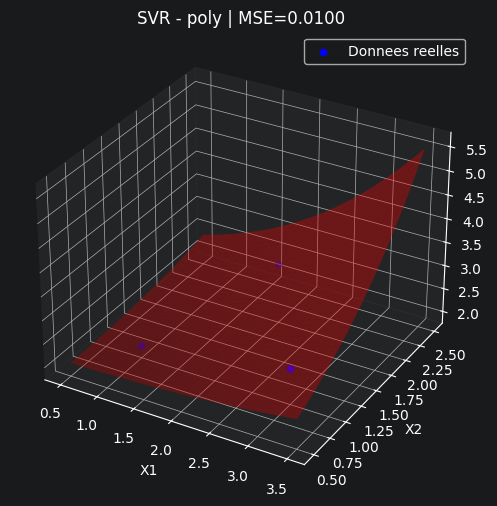

In [34]:
run_case_svr("Linear Simple 2D", X, Y, configs_kernels)
run_case_svr("Linear Simple 2D", X, Y, configs_c)
run_case_svr("Linear Simple 2D", X, Y, configs_epsilon)
run_case_svr("Linear Simple 2D", X, Y, configs_gamma)
run_case_svr("Linear Simple 2D", X, Y, configs_degree)


### Linear Tricky 3D :
        Linear Model    : OK
        MLP (2, 1)      : OK

In [35]:
X = np.array([
      [1, 1],
      [2, 2],
      [3, 3]
])
Y = np.array([
      1,
      2,
      3
])

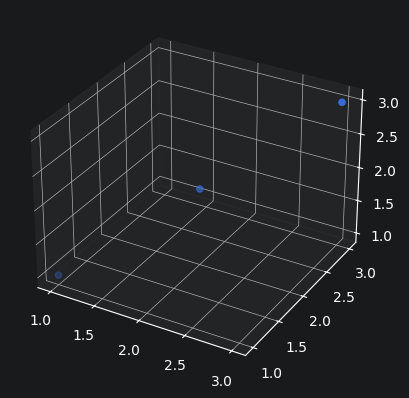

In [36]:
fig, ax = plt.subplots(subplot_kw={'projection': '3d'})
ax.scatter(X[:, 0], X[:, 1], Y)
plt.show()


Linear Simple 2D
linear | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.006667


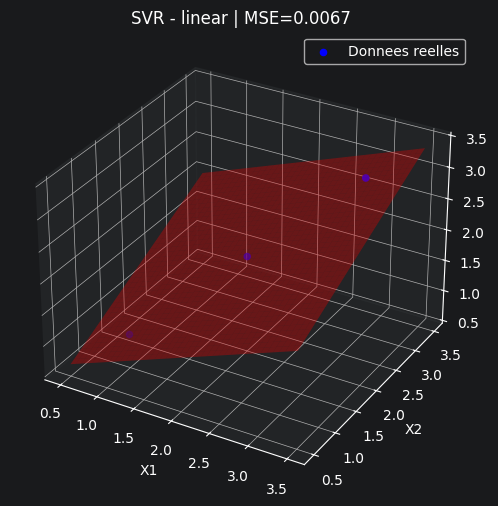


Linear Simple 2D
poly | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.010000


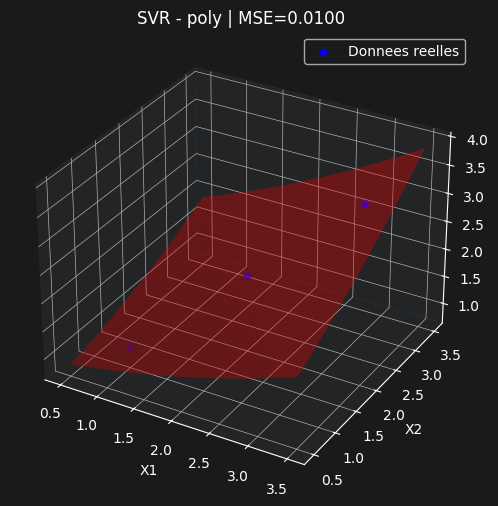


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.006667


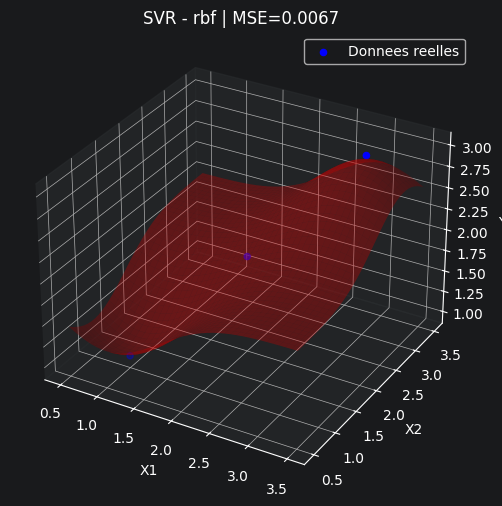


Linear Simple 2D
rbf | C=0.1 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.540040


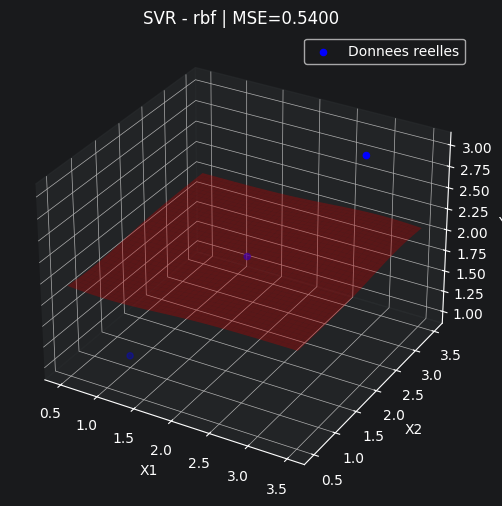


Linear Simple 2D
rbf | C=1 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.006667


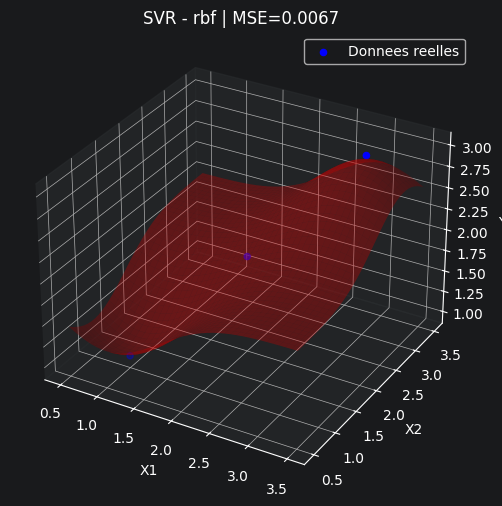


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.006667


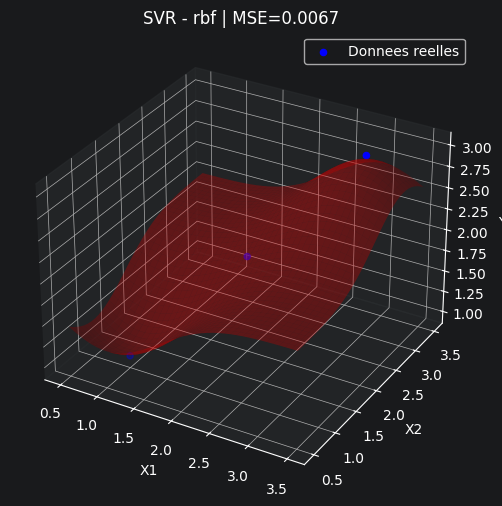


Linear Simple 2D
rbf | C=10 | epsilon=0.01 | gamma=1 | degree=2 | MSE=0.000067


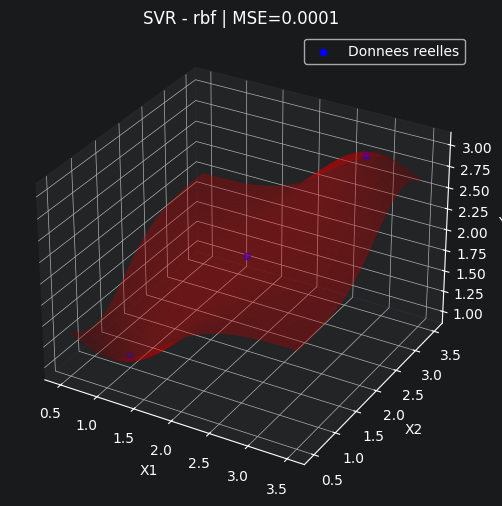


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.006667


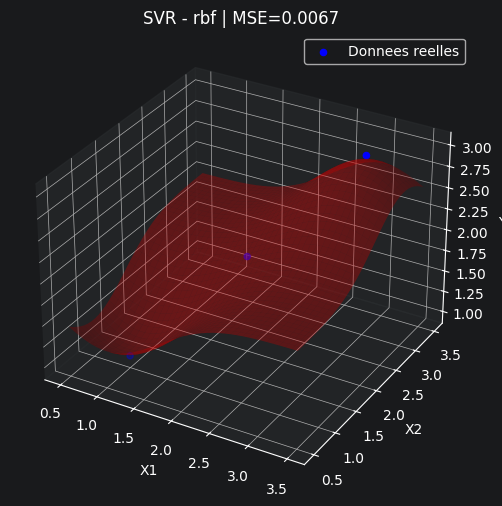


Linear Simple 2D
rbf | C=10 | epsilon=0.5 | gamma=1 | degree=2 | MSE=0.166667


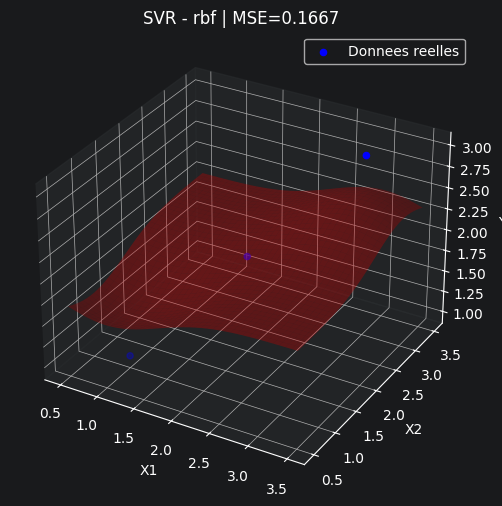


Linear Simple 2D
rbf | C=10 | epsilon=1 | gamma=1 | degree=2 | MSE=0.666667


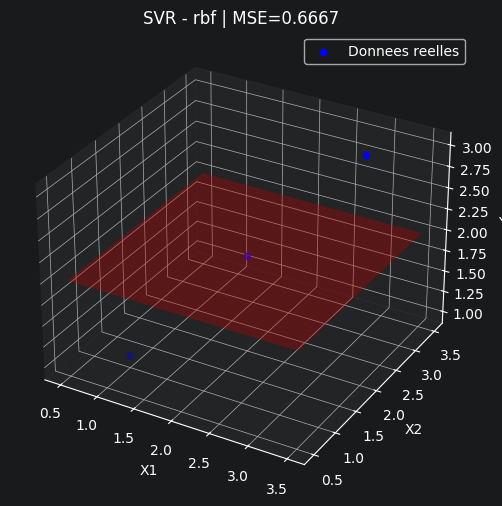


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=0.01 | degree=2 | MSE=0.035624


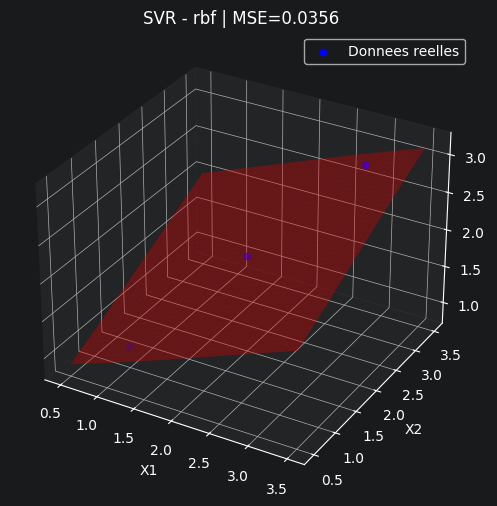


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=0.1 | degree=2 | MSE=0.006667


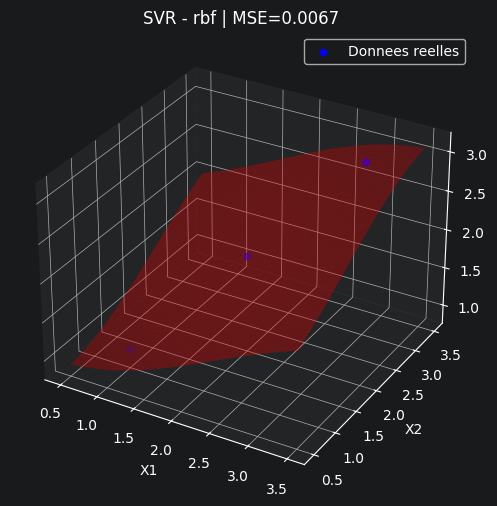


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.006667


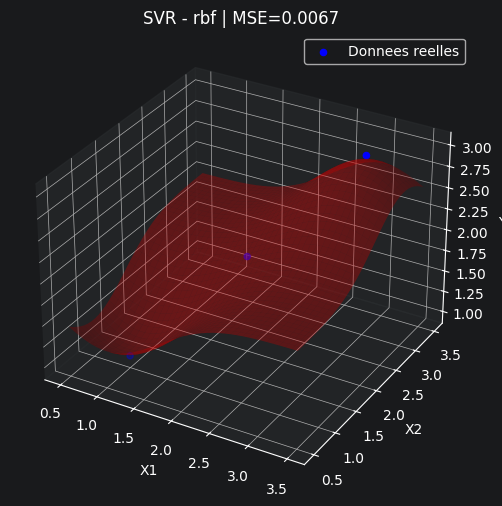


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=10 | degree=2 | MSE=0.006667


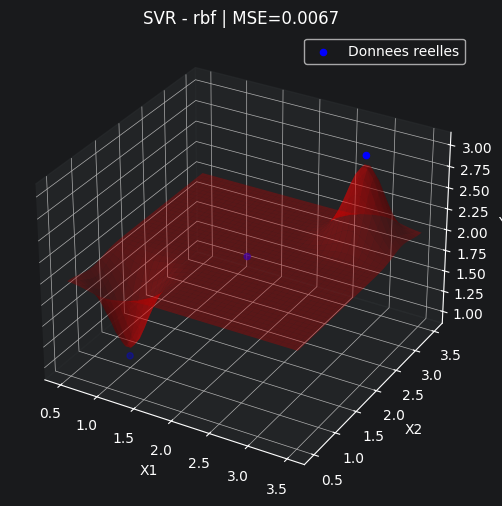


Linear Simple 2D
poly | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.010000


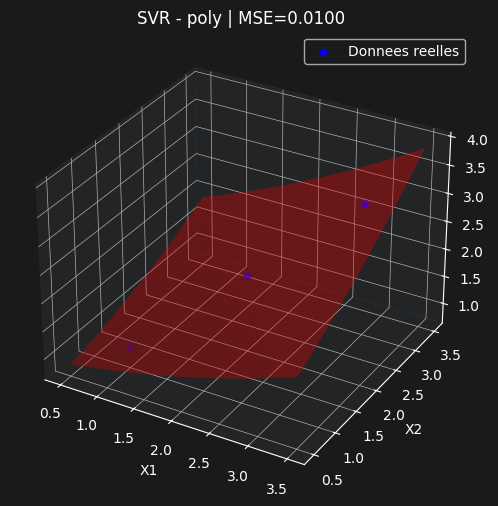


Linear Simple 2D
poly | C=10 | epsilon=0.1 | gamma=1 | degree=3 | MSE=0.010000


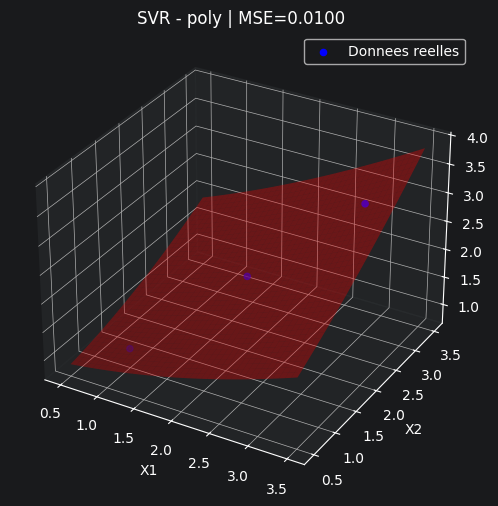


Linear Simple 2D
poly | C=10 | epsilon=0.1 | gamma=1 | degree=4 | MSE=0.010000


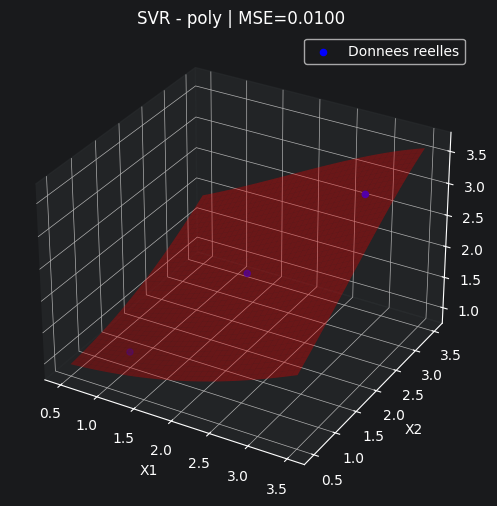

In [37]:
run_case_svr("Linear Simple 2D", X, Y, configs_kernels)
run_case_svr("Linear Simple 2D", X, Y, configs_c)
run_case_svr("Linear Simple 2D", X, Y, configs_epsilon)
run_case_svr("Linear Simple 2D", X, Y, configs_gamma)
run_case_svr("Linear Simple 2D", X, Y, configs_degree)

### Non Linear Simple 3D :
        Linear Model       : KO
        MLP (2, 2, 1)      : OK

In [38]:
X = np.array([
      [1, 0],
      [0, 1],
      [1, 1],
      [0, 0],
])
Y = np.array([
      2,
      1,
      -2,
      -1
])

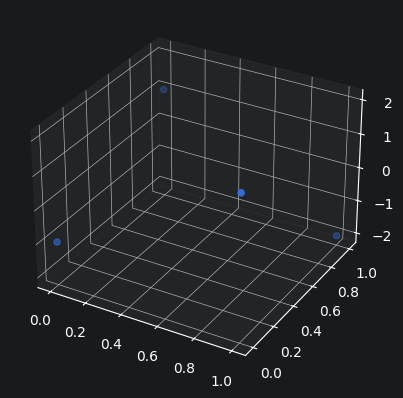

In [39]:
fig, ax = plt.subplots(subplot_kw={'projection': '3d'})
ax.scatter(X[:, 0], X[:, 1], Y)
plt.show()


Linear Simple 2D
linear | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=2.500000


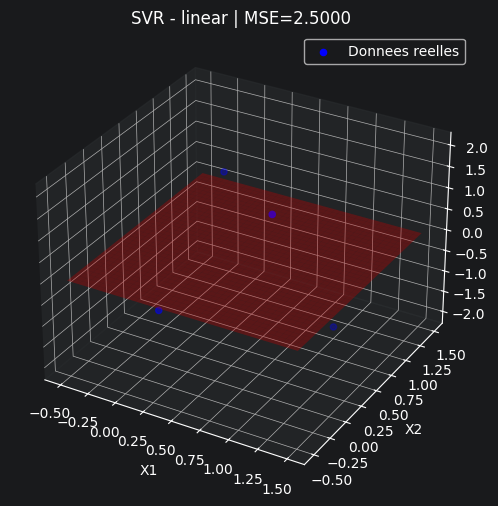


Linear Simple 2D
poly | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.010000


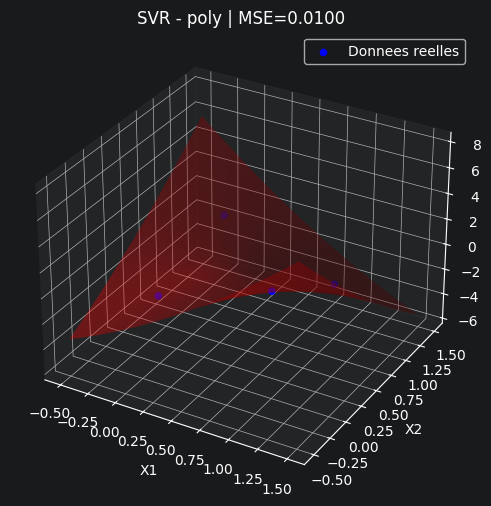


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.010000


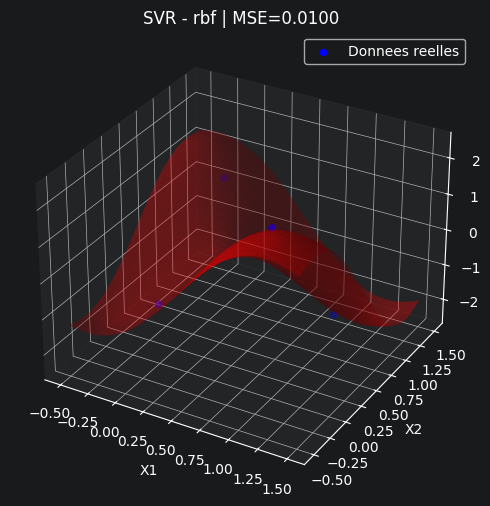


Linear Simple 2D
rbf | C=0.1 | epsilon=0.1 | gamma=1 | degree=2 | MSE=2.381724


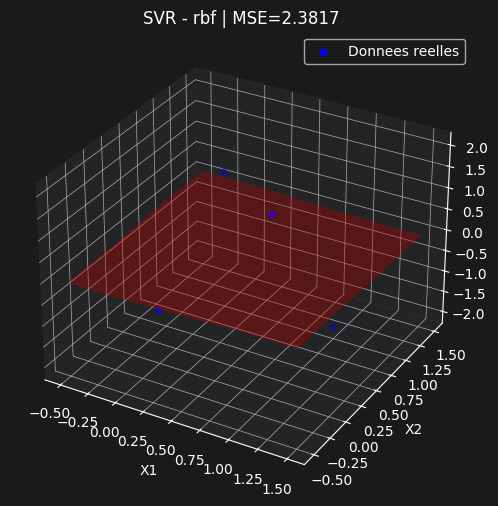


Linear Simple 2D
rbf | C=1 | epsilon=0.1 | gamma=1 | degree=2 | MSE=1.460932


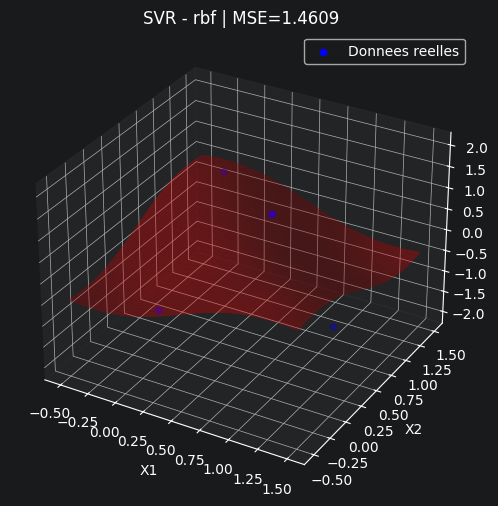


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.010000


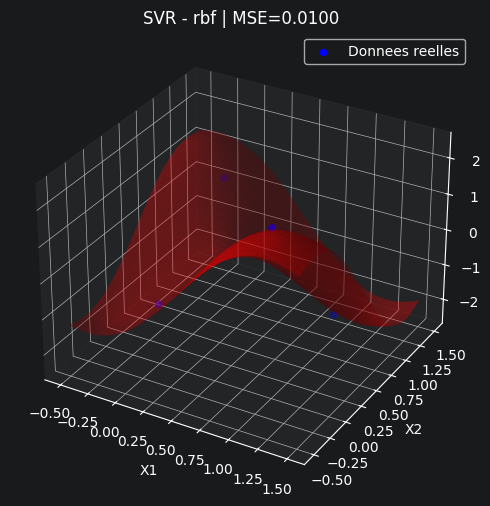


Linear Simple 2D
rbf | C=10 | epsilon=0.01 | gamma=1 | degree=2 | MSE=0.000100


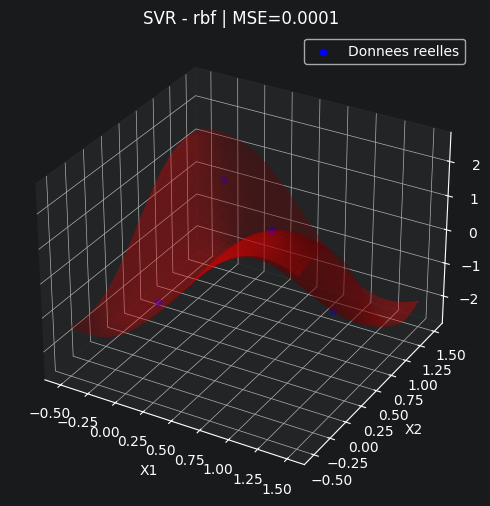


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.010000


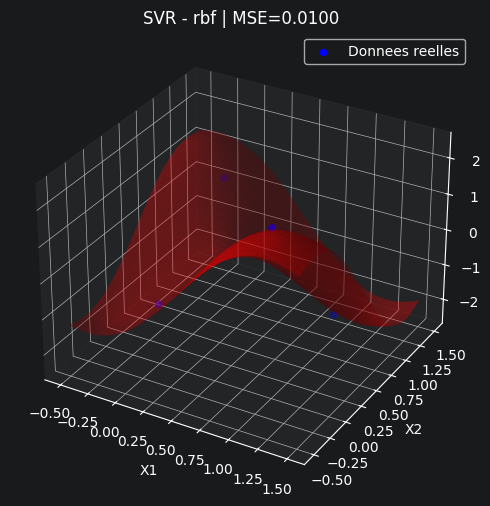


Linear Simple 2D
rbf | C=10 | epsilon=0.5 | gamma=1 | degree=2 | MSE=0.250000


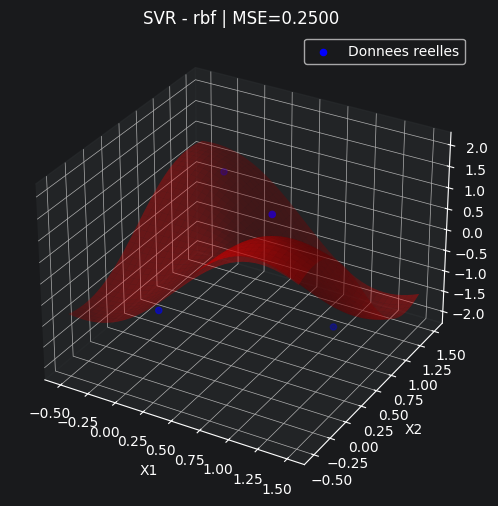


Linear Simple 2D
rbf | C=10 | epsilon=1 | gamma=1 | degree=2 | MSE=1.000000


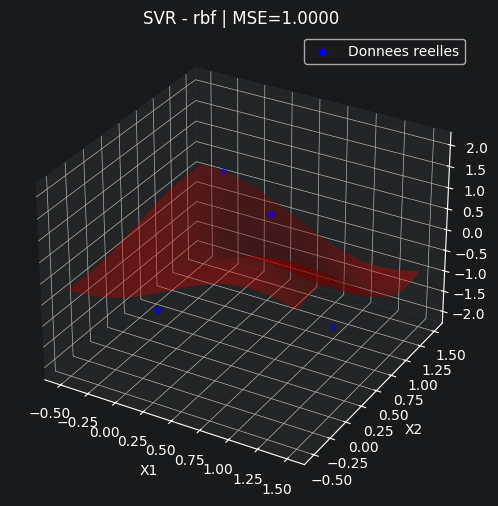


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=0.01 | degree=2 | MSE=2.497031


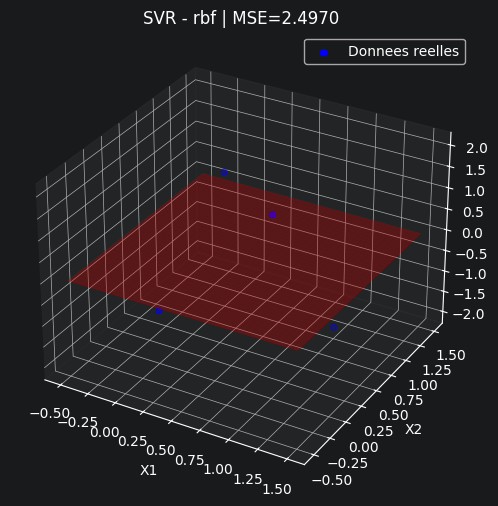


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=0.1 | degree=2 | MSE=2.236523


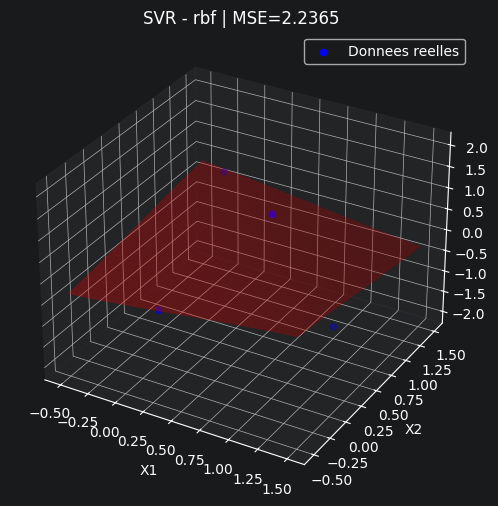


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.010000


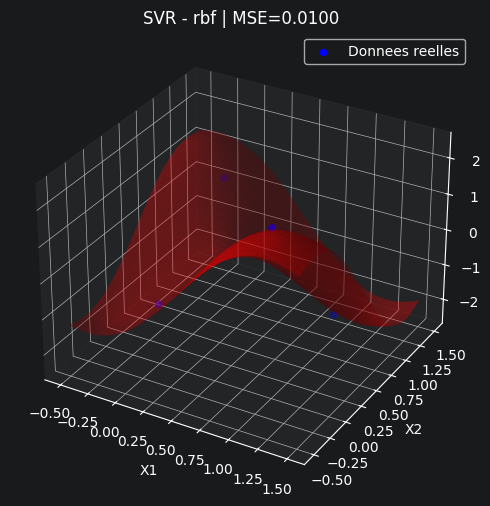


Linear Simple 2D
rbf | C=10 | epsilon=0.1 | gamma=10 | degree=2 | MSE=0.010000


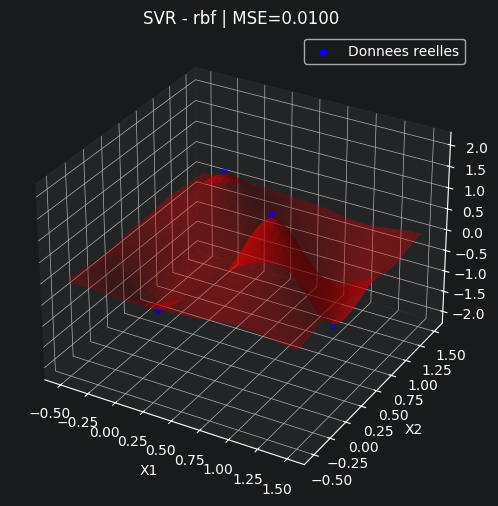


Linear Simple 2D
poly | C=10 | epsilon=0.1 | gamma=1 | degree=2 | MSE=0.010000


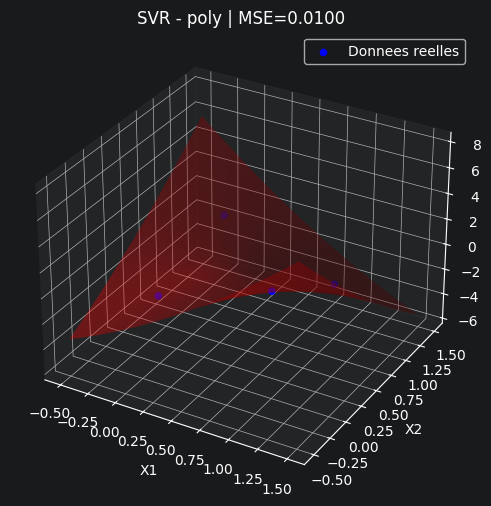


Linear Simple 2D
poly | C=10 | epsilon=0.1 | gamma=1 | degree=3 | MSE=0.010000


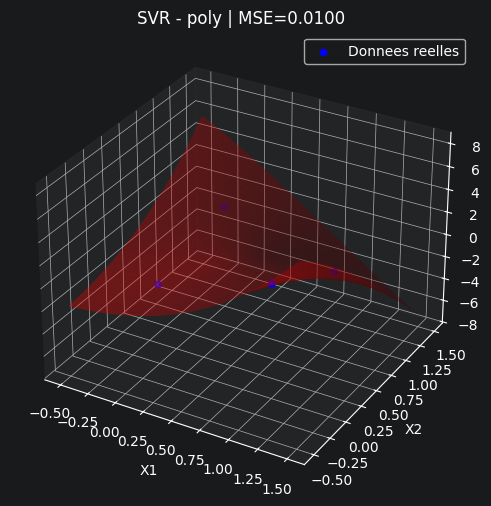


Linear Simple 2D
poly | C=10 | epsilon=0.1 | gamma=1 | degree=4 | MSE=0.010000


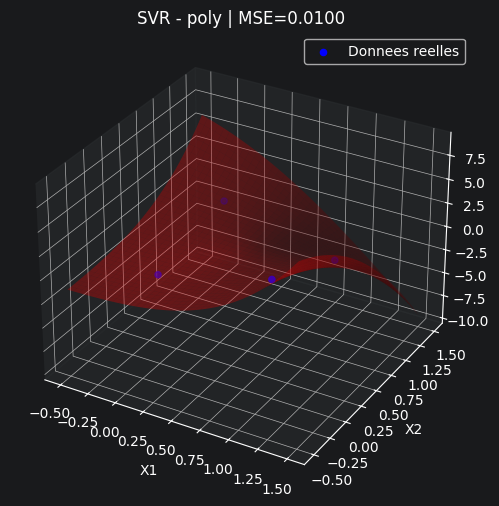

In [40]:
run_case_svr("Linear Simple 2D", X, Y, configs_kernels)
run_case_svr("Linear Simple 2D", X, Y, configs_c)
run_case_svr("Linear Simple 2D", X, Y, configs_epsilon)
run_case_svr("Linear Simple 2D", X, Y, configs_gamma)
run_case_svr("Linear Simple 2D", X, Y, configs_degree)
